# E-commerce Sales & Customer Behavior

**Portfolio project · SQL / BigQuery · Python / pandas · Statistical analysis**



In [ ]:
%pip install -q "google-cloud-bigquery[pandas]" scipy statsmodels seaborn


In [ ]:
from google.colab import auth
from google.cloud import bigquery
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
auth.authenticate_user()
client = bigquery.Client(project="data-analytics-mate")

plt.style.use("default")
sns.set_style("whitegrid")


In [ ]:
query = """
WITH session_data AS (
    SELECT
        s.date AS session_date,
        s.ga_session_id,
        sp.continent,
        sp.country,
        sp.device,
        sp.browser,
        sp.mobile_model_name,
        sp.operating_system,
        sp.language,
        sp.name AS traffic_name,
        sp.medium,
        sp.channel,
        a.id AS account_id,
        a.is_verified,
        a.is_unsubscribed
    FROM `DA.session` AS s
    LEFT JOIN `DA.session_params` AS sp
        ON s.ga_session_id = sp.ga_session_id
    LEFT JOIN `DA.account_session` AS acs
        ON s.ga_session_id = acs.ga_session_id
    LEFT JOIN `DA.account` AS a
        ON acs.account_id = a.id
),
purchase_data AS (
    SELECT
        o.ga_session_id,
        p.category,
        p.name AS product_name,
        p.price,
        p.short_description
    FROM `DA.order` AS o
    LEFT JOIN `DA.product` AS p
        ON o.item_id = p.item_id
)
SELECT
    s.session_date,
    s.ga_session_id,
    s.continent,
    s.country,
    s.device,
    s.browser,
    s.mobile_model_name,
    s.operating_system,
    s.language,
    s.traffic_name,
    s.medium,
    s.channel,
    s.account_id,
    s.is_verified,
    s.is_unsubscribed,
    p.category,
    p.product_name,
    p.price,
    p.short_description
FROM session_data AS s
LEFT JOIN purchase_data AS p
    ON s.ga_session_id = p.ga_session_id;
"""

df = client.query(query).to_dataframe(create_bqstorage_client=False)
df.head()


,session_date,ga_session_id,continent,country,device,browser,mobile_model_name,operating_system,language,traffic_name,medium,channel,account_id,is_verified,is_unsubscribed,category,product_name,price,short_description
0,2020-11-01,967742695,Americas,United States,desktop,Safari,Safari,Web,en-us,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,9065007548,Asia,China,desktop,Chrome,Safari,Web,None,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3267062634,Americas,United States,desktop,Chrome,Safari,Web,en-us,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
3,2020-11-01,8892952409,Americas,United States,mobile,Android Webview,<Other>,Web,ko,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,None,None,NaN,None
4,2020-11-01,1624570787,Asia,Turkey,desktop,<Other>,<Other>,Web,en-us,(data deleted),(data deleted),Undefined,<NA>,<NA>,<NA>,None,None,NaN,None


## 3. Sales drivers

Rankings use the recorded price sum as the revenue estimate. Purchase counts
refer to purchasing sessions, with a non-null `price`.

### 3.1 Continents


In [ ]:
continent_summary = (
    df.groupby("continent", as_index=False)
    .agg(total_revenue=("price", "sum"), purchasing_sessions=("price", "count")))

top_continent = continent_summary.nlargest(3, "total_revenue")
top_continent_purchases = continent_summary.nlargest(3, "purchasing_sessions")

print("Top 3 continents by estimated revenue:")
display(top_continent.round(2))
print("Top 3 continents by purchasing sessions:")
display(top_continent_purchases.round(2))


Top 3 continents by estimated revenue:


,continent,total_revenue,purchasing_sessions
2,Americas,17665280.0,18553
3,Asia,7601298.3,7950
4,Europe,5934624.2,6261


Top 3 continents by purchasing sessions:


,continent,total_revenue,purchasing_sessions
2,Americas,17665280.0,18553
3,Asia,7601298.3,7950
4,Europe,5934624.2,6261


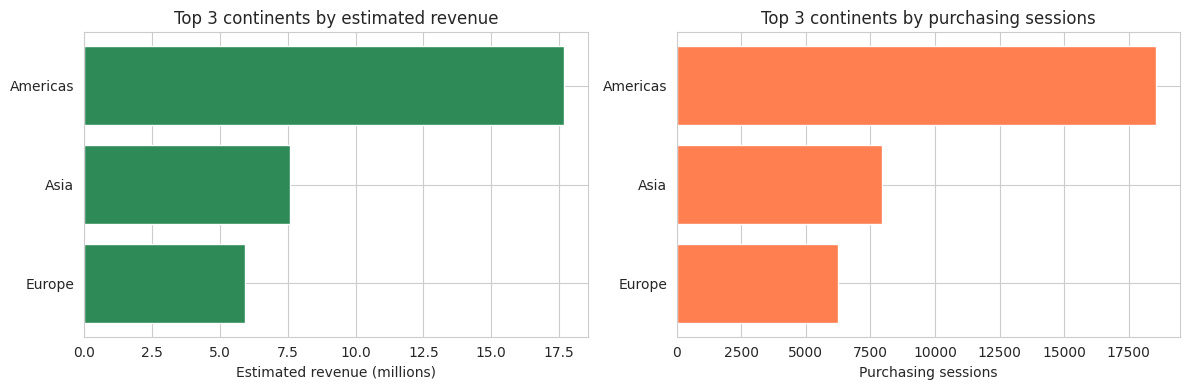

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(top_continent["continent"], top_continent["total_revenue"] / 1_000_000, color="seagreen")
axes[0].set(title="Top 3 continents by estimated revenue", xlabel="Estimated revenue (millions)")
axes[0].invert_yaxis()
axes[1].barh(top_continent_purchases["continent"], top_continent_purchases["purchasing_sessions"], color="coral")
axes[1].set(title="Top 3 continents by purchasing sessions", xlabel="Purchasing sessions")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


**Readout.** The Americas lead both rankings: 17.67 million in estimated
revenue and 18,553 purchasing sessions. Asia follows with 7.60 million and
7,950 sessions; Europe records 5.93 million and 6,261. The same three continents
lead by both measures. These are recorded purchase-session counts.


### 3.2 Countries


In [ ]:
country_summary = (
    df.groupby("country", as_index=False)
    .agg(total_revenue=("price", "sum"), purchasing_sessions=("price", "count"))
)

top_country = country_summary.nlargest(5, "total_revenue")
top_country_purchases = country_summary.nlargest(5, "purchasing_sessions")

print("Top 5 countries by estimated revenue:")
display(top_country.round(2))
print("Top 5 countries by purchasing sessions:")
display(top_country_purchases.round(2))


Top 5 countries by estimated revenue:


,country,total_revenue,purchasing_sessions
104,United States,13943553.9,14673
43,India,2809762.0,3029
18,Canada,2437921.0,2560
103,United Kingdom,938317.9,1029
33,France,710692.8,678


Top 5 countries by purchasing sessions:


,country,total_revenue,purchasing_sessions
104,United States,13943553.9,14673
43,India,2809762.0,3029
18,Canada,2437921.0,2560
103,United Kingdom,938317.9,1029
33,France,710692.8,678


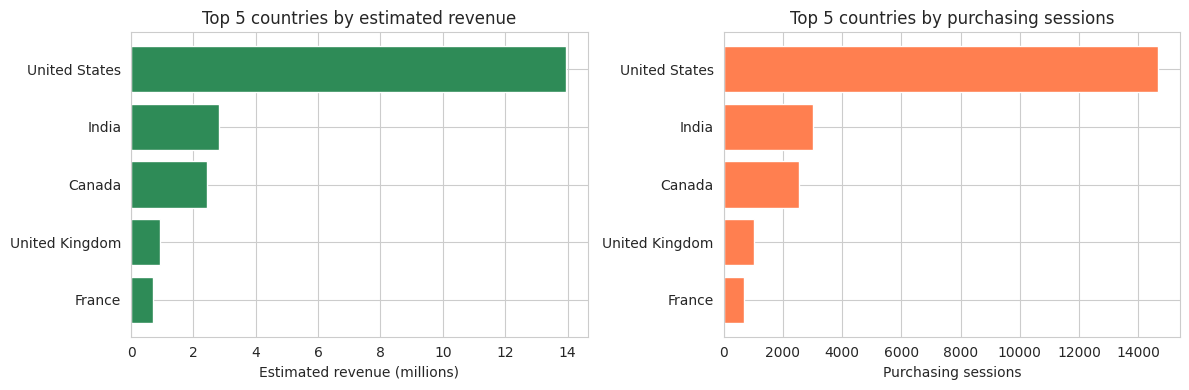

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(top_country["country"], top_country["total_revenue"] / 1_000_000, color="seagreen")
axes[0].set(title="Top 5 countries by estimated revenue", xlabel="Estimated revenue (millions)")
axes[0].invert_yaxis()
axes[1].barh(top_country_purchases["country"], top_country_purchases["purchasing_sessions"], color="coral")
axes[1].set(title="Top 5 countries by purchasing sessions", xlabel="Purchasing sessions")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


**Readout.** The United States leads with 13.94 million in estimated revenue
(43.61% of the total) and 14,673 purchasing sessions. India and Canada
follow. The top five countries have the same ordering by the price sum and by
purchasing-session count.


### 3.3 Product categories


In [ ]:
top_category = (
    df.groupby("category", as_index=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values("total_revenue", ascending=False)
    .head(10))

display(top_category.round(2))


,category,total_revenue
12,Sofas & armchairs,8388254.5
5,Chairs,6147748.8
1,Beds,4919725.0
2,Bookcases & shelving units,3640818.1
3,Cabinets & cupboards,2336499.5
9,Outdoor furniture,2142222.2
13,Tables & desks,1790307.5
6,Chests of drawers & drawer units,906562.5
0,Bar furniture,735503.0
7,Children's furniture,467697.0


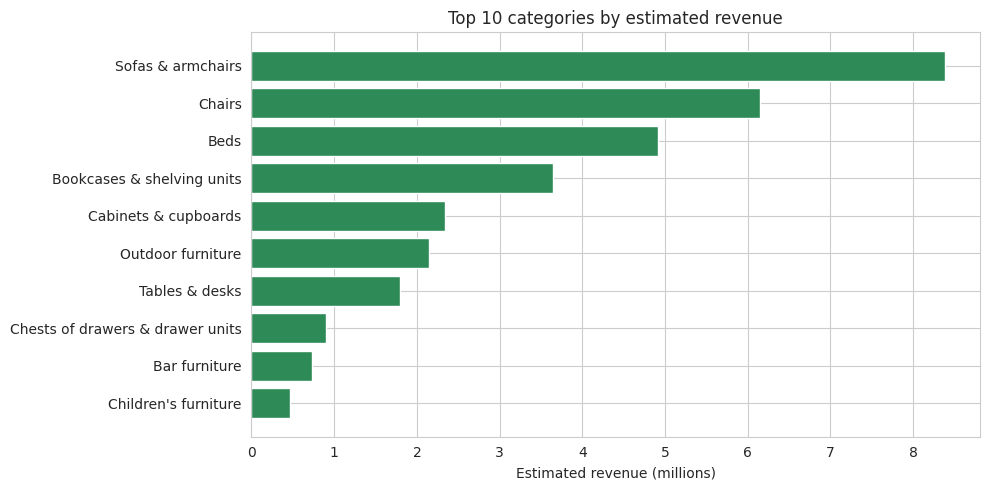

In [ ]:
plt.figure(figsize=(10, 5))
plt.barh(top_category["category"], top_category["total_revenue"] / 1_000_000, color="seagreen")
plt.gca().invert_yaxis()
plt.title("Top 10 categories by estimated revenue")
plt.xlabel("Estimated revenue (millions)")
plt.tight_layout()
plt.show()


**Readout.** Sofas & armchairs lead with 8.39 million, followed by Chairs
(6.15 million) and Beds (4.92 million). Together, these three categories account
for 60.85% of the revenue estimate; the displayed top
ten account for 98.45%.


### 3.4 Category mix in the leading country


In [ ]:
leader_country = top_country.iloc[0]["country"]

top_category_country = (
    df[df["country"] == leader_country]
    .groupby("category", as_index=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

print("Country with the highest revenue:", leader_country)
display(top_category_country.round(2))

global_categories = top_category["category"].tolist()
country_categories = top_category_country["category"].tolist()

print("Same categories in both top 10 lists:",
      set(global_categories) == set(country_categories))
print("Same category ranking:",
      global_categories == country_categories)


Country with the highest revenue: United States


,category,total_revenue
12,Sofas & armchairs,3707144.5
5,Chairs,2619773.8
1,Beds,2213058.0
2,Bookcases & shelving units,1567606.9
3,Cabinets & cupboards,994545.5
9,Outdoor furniture,929245.2
13,Tables & desks,777865.0
6,Chests of drawers & drawer units,382388.0
0,Bar furniture,330805.0
7,Children's furniture,207575.0


Same categories in both top 10 lists: True
Same category ranking: True


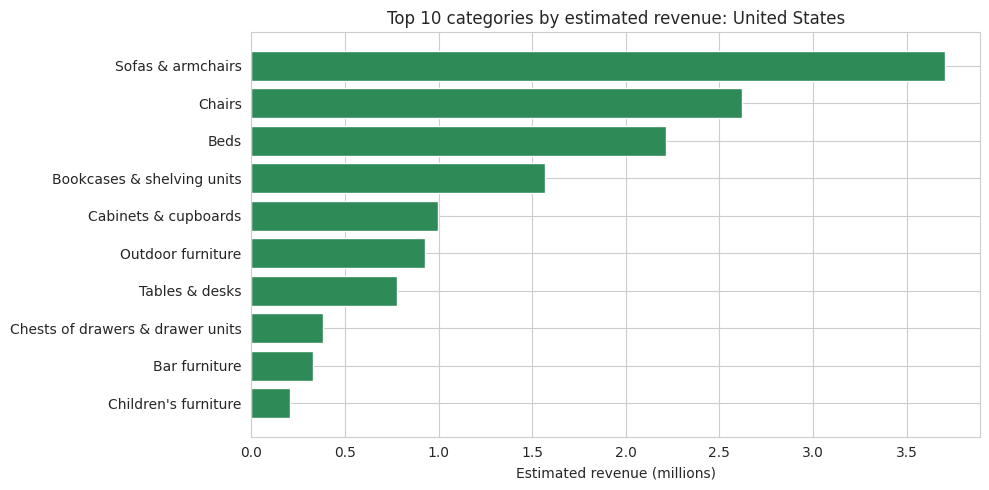

In [ ]:
plt.figure(figsize=(10, 5))
plt.barh(top_category_country["category"], top_category_country["total_revenue"] / 1_000_000, color="seagreen")
plt.gca().invert_yaxis()
plt.title(f"Top 10 categories by estimated revenue: {leader_country}")
plt.xlabel("Estimated revenue (millions)")
plt.tight_layout()
plt.show()


**Readout.** The United States has the same top-ten category set and the same
ranking as the global result. Sofas & armchairs lead the US category ranking at
3.71 million, followed by Chairs at 2.62 million and Beds at 2.21 million.


### 3.5 Device types


In [ ]:
total_revenue = df["price"].sum()

device_sales = (
    df.groupby("device", as_index=False, dropna=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values("total_revenue", ascending=False)
)

device_sales["revenue_share_pct"] = (
    device_sales["total_revenue"] / total_revenue * 100
)

display(device_sales.round(2))


,device,total_revenue,revenue_share_pct
0,desktop,18864039.0,59.00
1,mobile,12384225.8,38.73
2,tablet,723466.3,2.26


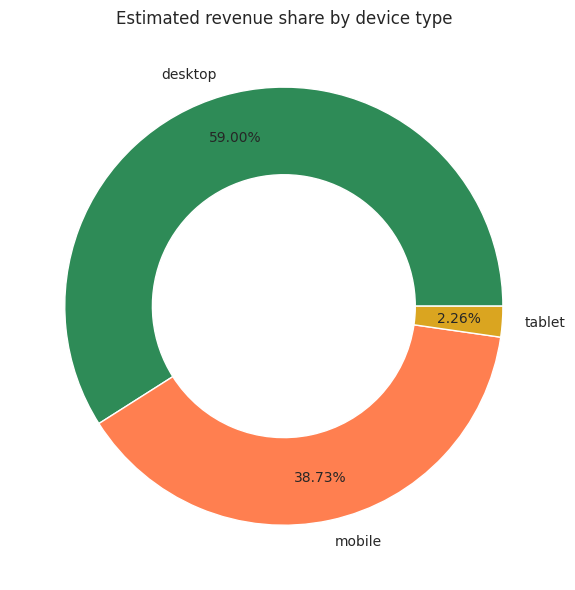

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(device_sales["total_revenue"], labels=device_sales["device"],
        colors=["seagreen", "coral", "goldenrod"], autopct="%.2f%%",
        wedgeprops={"width": 0.4}, pctdistance=0.8)
plt.title("Estimated revenue share by device type")
plt.tight_layout()
plt.show()


**Readout.** Desktop contributes 59.00% of the revenue estimate, mobile
38.73%, and tablet 2.26%. Desktop and mobile together represent almost all of
the recorded price sum; the tablet segment is comparatively small.


### 3.6 Reported device/model labels


In [ ]:
total_revenue = df["price"].sum()

model_sales = (
    df.groupby("mobile_model_name", as_index=False, dropna=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values("total_revenue", ascending=False)
)

model_sales["revenue_share_pct"] = (
    model_sales["total_revenue"] / total_revenue * 100)

display(model_sales.round(2))


,mobile_model_name,total_revenue,revenue_share_pct
1,Chrome,8899523.9,27.84
0,<Other>,6535330.8,20.44
7,Safari,6491062.1,20.30
9,iPhone,6420776.3,20.08
2,ChromeBook,1830458.7,5.73
3,Edge,697222.3,2.18
8,iPad,448854.2,1.40
4,Firefox,421066.9,1.32
6,Pixel 4 XL,118287.7,0.37
5,Pixel 3,109148.2,0.34


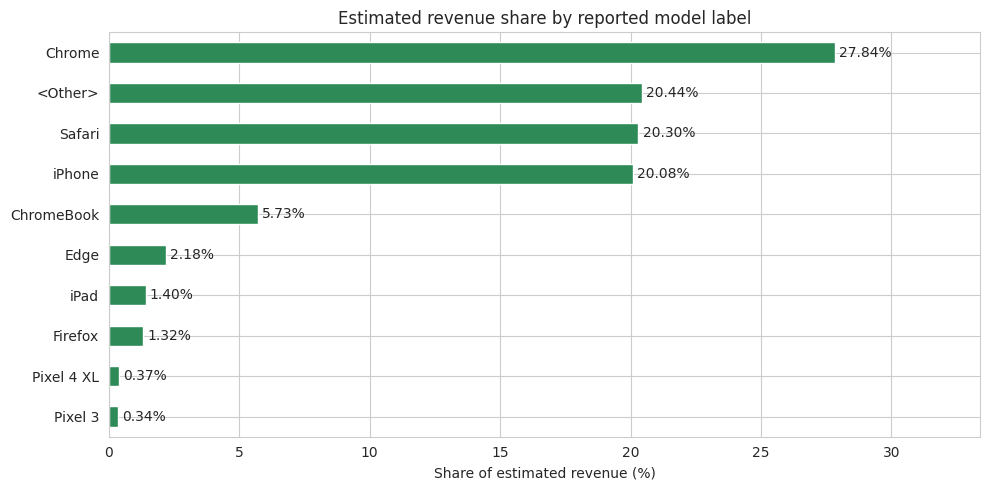

In [ ]:
ax = model_sales.head(10).plot.barh(
    x="mobile_model_name", y="revenue_share_pct", color="seagreen", legend=False,
    figsize=(10, 5), title="Estimated revenue share by reported model label", xlabel="Share of estimated revenue (%)")
ax.invert_yaxis()
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()


**Readout.** The largest source labels are Chrome (27.84%), `<Other>`
(20.44%), Safari (20.30%), and iPhone (20.08%). The field is
`mobile_model_name`, but it contains browser-like labels alongside hardware
labels. This result describes the reported source labels; a hardware-model
interpretation requires checking the field's definition.


### 3.7 Traffic source labels


In [ ]:
total_revenue = df["price"].sum()

traffic_sales = (
    df.groupby("traffic_name", as_index=False, dropna=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values("total_revenue", ascending=False)
)

traffic_sales["revenue_share_pct"] = (
    traffic_sales["total_revenue"] / total_revenue * 100
)

display(traffic_sales.round(2))


,traffic_name,total_revenue,revenue_share_pct
2,(organic),10935239.9,34.20
1,(direct),7494923.4,23.44
4,<Other>,5897375.6,18.45
3,(referral),5641855.2,17.65
0,(data deleted),2002337.0,6.26


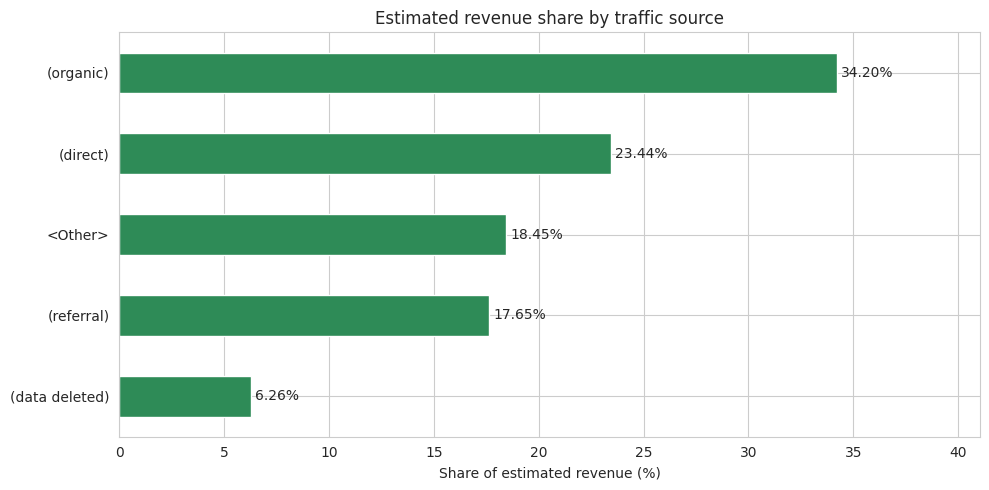

In [ ]:
ax = traffic_sales.head(10).plot.barh(
    x="traffic_name", y="revenue_share_pct", color="seagreen", legend=False,
    figsize=(10, 5), title="Estimated revenue share by traffic source", xlabel="Share of estimated revenue (%)")
ax.invert_yaxis()
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()


**Readout.** The `(organic)` source label contributes 34.20% of the revenue
estimate, followed by `(direct)` at 23.44%. `<Other>` accounts for 18.45% and
`(data deleted)` for 6.26%, limiting more detailed source interpretation.
These source labels are separate from the traffic-channel analysis below.


## 4. Registered-user profiles

Account-level measures count distinct registered accounts represented in the
extract. Their denominators exclude guest sessions.

### 4.1 Email verification


In [ ]:
registered_users = df["account_id"].nunique()

verified_users = df.loc[
    df["is_verified"] == 1, "account_id"
].nunique()

verified_share_pct = verified_users / registered_users * 100

print(f"Registered users: {registered_users:,}")
print(f"Users with verified email: {verified_users:,}")
print(f"Verified email share: {verified_share_pct:.2f}%")


Registered users: 27,945
Users with verified email: 20,036
Verified email share: 71.70%


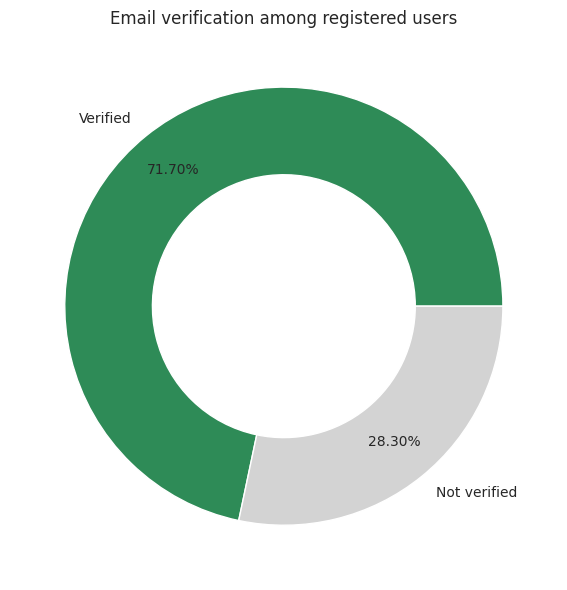

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie([verified_users, registered_users - verified_users],
        labels=["Verified", "Not verified"], colors=["seagreen", "lightgray"],
        autopct="%.2f%%", wedgeprops={"width": 0.4}, pctdistance=0.8)
plt.title("Email verification among registered users")
plt.tight_layout()
plt.show()


**Readout.** Of 27,945 unique registered accounts represented in the extract,
20,036 have a verified email address: **71.70%**. Each account is counted once;
guest sessions are excluded from this denominator.


### 4.2 Newsletter subscription


In [ ]:
registered_users = df["account_id"].nunique()

unsubscribed_users = df.loc[
    df["is_unsubscribed"] == 1, "account_id"
].nunique()

unsubscribed_share_pct = unsubscribed_users / registered_users * 100

print(f"Registered users: {registered_users:,}")
print(f"Unsubscribed users: {unsubscribed_users:,}")
print(f"Unsubscribed user share: {unsubscribed_share_pct:.2f}%")


Registered users: 27,945
Unsubscribed users: 4,735
Unsubscribed user share: 16.94%


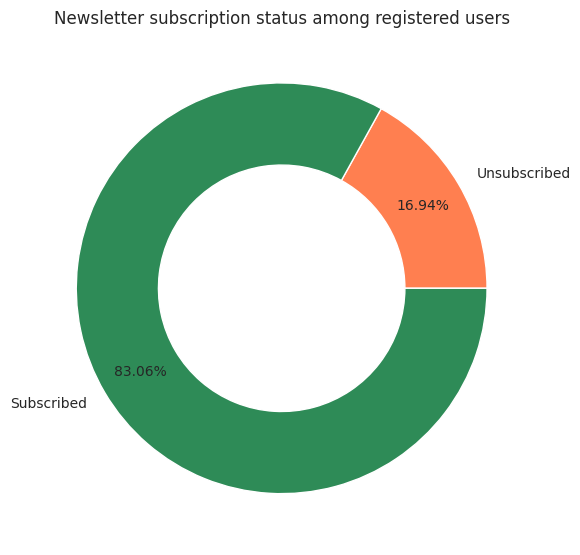

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie([unsubscribed_users, registered_users - unsubscribed_users],
        labels=["Unsubscribed", "Subscribed"], colors=["coral", "seagreen"],
        autopct="%.2f%%", wedgeprops={"width": 0.4}, pctdistance=0.8)
plt.title("Newsletter subscription status among registered users")
plt.tight_layout()
plt.show()


**Readout.** The extract contains 4,735 unsubscribed accounts (**16.94%**)
and 23,210 subscribed accounts (**83.06%**), out of 27,945 unique registered
accounts. These are the recorded subscription states.


### 4.3 Purchasing measures by subscription status


In [ ]:
user_sales = (
    df.dropna(subset=["account_id"])
    .groupby(["account_id", "is_unsubscribed"], as_index=False)
    .agg(
        total_revenue=("price", "sum"),
        purchasing_sessions=("price", "count")
    )
)

user_sales["subscription_status"] = user_sales["is_unsubscribed"].map(
    {0: "Subscribed", 1: "Unsubscribed"}
)
user_sales["is_buyer"] = user_sales["purchasing_sessions"] > 0

subscription_comparison = (
    user_sales.groupby("subscription_status", as_index=False)
    .agg(
        users=("account_id", "nunique"),
        buyers=("is_buyer", "sum"),
        total_revenue=("total_revenue", "sum"),
        purchasing_sessions=("purchasing_sessions", "sum"),
        revenue_per_user=("total_revenue", "mean")
    )
)

subscription_comparison["buyer_share_pct"] = (
    subscription_comparison["buyers"]
    / subscription_comparison["users"] * 100
)

display(subscription_comparison.round(2))


,subscription_status,users,buyers,total_revenue,purchasing_sessions,revenue_per_user,buyer_share_pct
0,Subscribed,23210,2334,2150796.9,2334,92.67,10.06
1,Unsubscribed,4735,447,431721.6,447,91.18,9.44


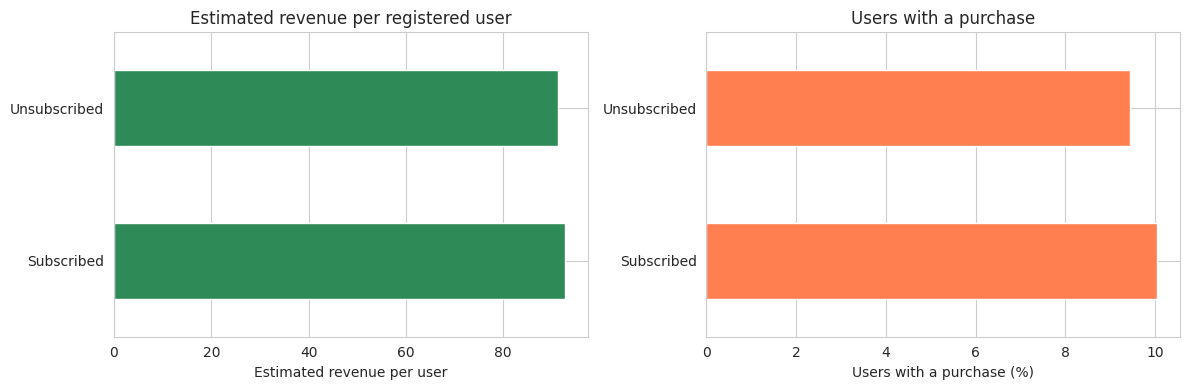

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
subscription_comparison.plot.barh(x="subscription_status", y="revenue_per_user", ax=axes[0],
    color="seagreen", legend=False, title="Estimated revenue per registered user", xlabel="Estimated revenue per user")
subscription_comparison.plot.barh(x="subscription_status", y="buyer_share_pct", ax=axes[1],
    color="coral", legend=False, title="Users with a purchase", xlabel="Users with a purchase (%)")
axes[0].set_ylabel("")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
subscription_status,,,,,,,,
Subscribed,23210.0,92.67,502.99,0.0,0.0,0.0,0.0,8900.0
Unsubscribed,4735.0,91.18,488.40,0.0,0.0,0.0,0.0,8900.0


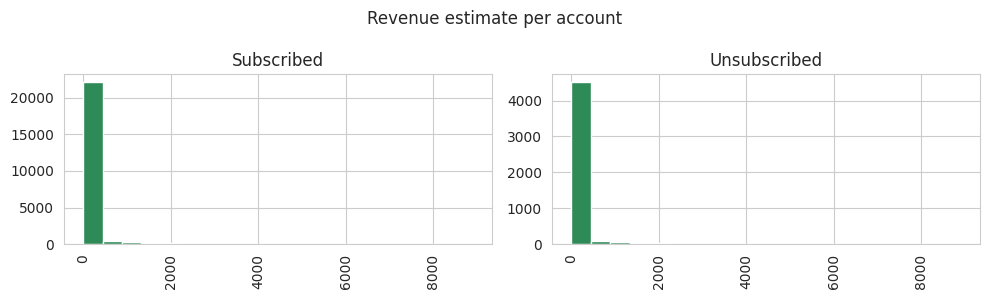

In [ ]:
display(
    user_sales.groupby("subscription_status")["total_revenue"]
    .describe().round(2)
)

user_sales.hist(
    column="total_revenue", by="subscription_status",
    bins=20, figsize=(10, 3), color="seagreen"
)
plt.suptitle("Revenue estimate per account")
plt.tight_layout()
plt.show()

**Method selection.** Each registered account is represented once, including
accounts without a recorded purchase. The two-proportion z-test compares the
shares of accounts with a purchase. The two-sided Mann-Whitney U test compares
the distributions of total revenue estimates per account, including zeros.
It is not a direct test of the difference between mean revenue estimates.

The two subscription groups are treated as independent account samples.
For these two tests, the Bonferroni-adjusted significance threshold is
0.05 / 2 = **0.025**.


In [ ]:
from statsmodels.stats.proportion import proportions_ztest

z_stat, p_buyers = proportions_ztest(
    subscription_comparison["buyers"],
    subscription_comparison["users"]
)

print("Z-statistic:", z_stat)
print("Buyer share p-value:", p_buyers)

Z-statistic: 1.2897602654930744
Buyer share p-value: 0.19713390786902185


In [ ]:
from scipy.stats import mannwhitneyu

subscribed_revenue = user_sales.loc[
    user_sales["is_unsubscribed"] == 0, "total_revenue"
]
unsubscribed_revenue = user_sales.loc[
    user_sales["is_unsubscribed"] == 1, "total_revenue"
]

u_stat, p_revenue = mannwhitneyu(
    subscribed_revenue, unsubscribed_revenue,
    alternative="two-sided"
)

print("Revenue distribution p-value:", p_revenue)

Revenue distribution p-value: 0.2279139907980643



**Readout.** Subscribed accounts have a slightly higher buyer share (10.06% vs 9.44%) and mean revenue estimate per account (92.67 vs 91.18).

However, the two-proportion z-test does not detect a statistically significant difference in buyer shares (**z = 1.290, p = 0.197**). The Mann–Whitney U test also does not detect a difference in account-level revenue distributions (**p = 0.228**). Both p-values exceed the Bonferroni-adjusted significance threshold of **0.025** for these two tests.

The observed differences remain descriptive. These results do not establish that the groups have identical purchasing behavior.

### 4.4 Countries with registered users


In [ ]:
registered_countries = (
    df.dropna(subset=["account_id"])
    .groupby("country", as_index=False, dropna=False)
    .agg(registered_users=("account_id", "nunique"))
    .sort_values("registered_users", ascending=False)
)

display(registered_countries)


,country,registered_users
104,United States,12384
43,India,2687
18,Canada,2067
103,United Kingdom,859
33,France,553
...,...,...
39,Honduras,4
77,Paraguay,4
64,Mongolia,4
98,Trinidad & Tobago,4


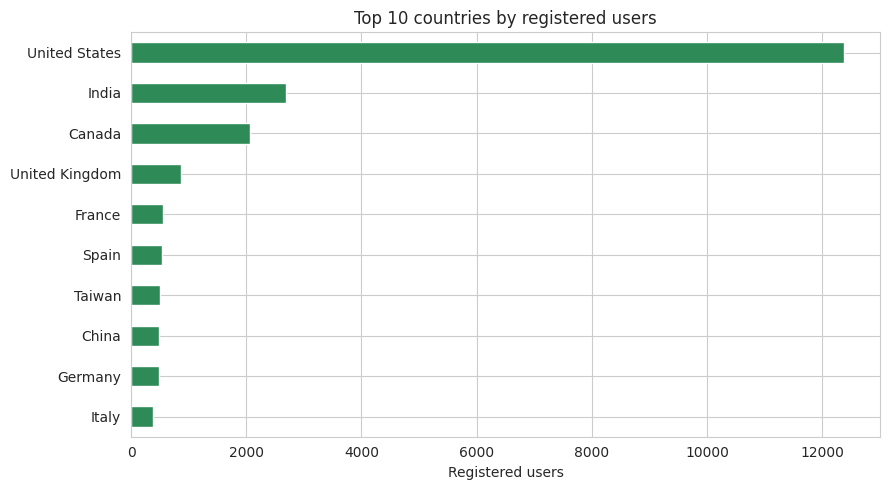

In [ ]:
ax = registered_countries.head(10).plot.barh(
    x="country", y="registered_users", color="seagreen", legend=False,
    figsize=(9, 5), title="Top 10 countries by registered users", xlabel="Registered users")
ax.invert_yaxis()
ax.set_ylabel("")
plt.tight_layout()
plt.show()


**Readout.** The United States has the largest represented registered-user
count (12,384), followed by India (2,687) and Canada (2,067). Accounts are
counted once within each recorded country. The chart displays the ten leading
countries.


## 5. Sales over time

These descriptive charts show the full 92-day session window. The final four
dates have no purchase records and remain visibly qualified in the discussion.

### 5.1 Daily estimates


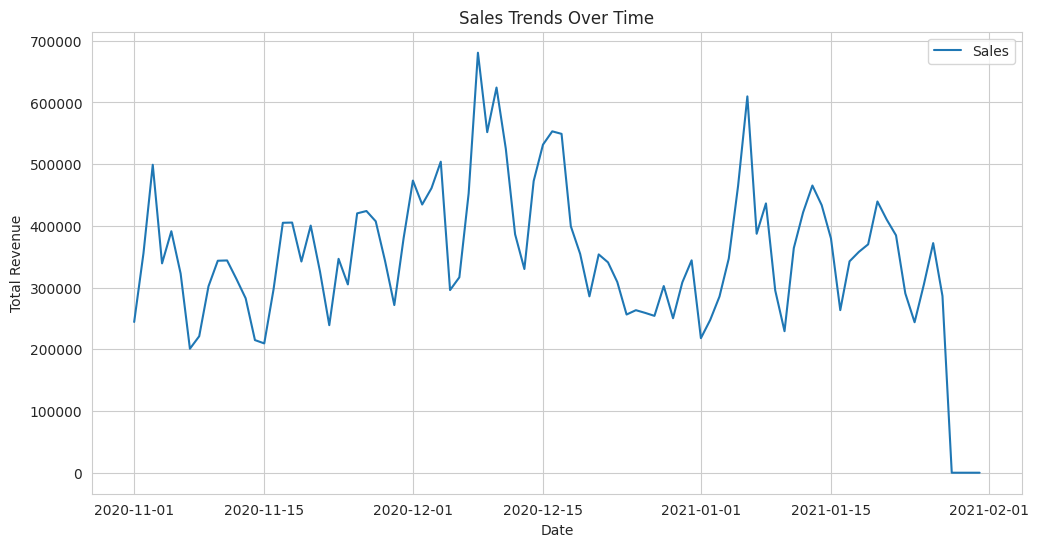

In [ ]:
sales_over_time = df.groupby("session_date").agg(Total_Revenue=("price", "sum"))

plt.figure(figsize=(12, 6))
plt.plot(sales_over_time.index, sales_over_time.values, label="Sales")
plt.xlabel("Date")
plt.ylabel("Total Revenue")
plt.title("Sales Trends Over Time")
plt.legend()
plt.grid(True)
plt.show()


**Readout.** Daily estimates fluctuate substantially, with the largest peak
around December 8 (about 680.5 thousand) and another peak around January 6
(about 609.8 thousand). The series does not show a sustained increase across
the full window. January 28–31 display zero summed prices because purchase
records are absent; their completeness is unresolved.


### 5.2 Average daily estimates by weekday


In [ ]:
df_sales = df.groupby("session_date").agg(total_revenue=("price", "sum"))
df_sales.index = pd.to_datetime(df_sales.index)
df_sales["day_of_week"] = df_sales.index.dayofweek

day_of_week_sales = df_sales.groupby("day_of_week")["total_revenue"].mean().round(0)
day_of_week_sales.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]


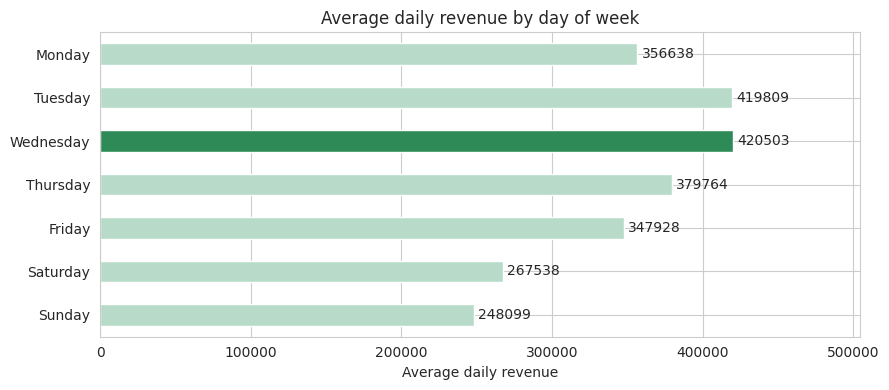

In [ ]:
colors = ["#B7DBC8"] * 7
colors[day_of_week_sales.argmax()] = "seagreen"
ax = day_of_week_sales.plot.barh(
    color=colors, figsize=(9, 4),
    title="Average daily revenue by day of week", xlabel="Average daily revenue")
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.margins(x=0.2)
plt.tight_layout()
plt.show()


**Readout.** Wednesday (420,503) and Tuesday (419,809) have almost identical
average daily estimates. Weekend averages are lower: 267,538 on Saturday and
248,099 on Sunday. This full-window summary includes the four unverified
end-of-January zeros. The next chart checks the pattern within complete weeks.


### 5.3 Consistency across complete weeks


In [ ]:
daily_sales = df_sales.rename(columns={"total_revenue": "Total_Revenue"}).copy()
daily_sales["week_start"] = daily_sales.index.to_period("W-SUN").start_time
daily_sales["day_of_week"] = daily_sales.index.dayofweek

weekly_revenue = daily_sales.pivot(
    index="week_start", columns="day_of_week", values="Total_Revenue"
).reindex(columns=range(7)).sort_index()
weekly_revenue.columns = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
]
display(weekly_revenue.round(0))


,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
week_start,,,,,,,
2020-10-26,NaN,NaN,NaN,NaN,NaN,NaN,244292.0
2020-11-02,355507.0,498980.0,339187.0,391277.0,322642.0,200892.0,221162.0
2020-11-09,302050.0,343472.0,343941.0,314070.0,282575.0,214889.0,209536.0
2020-11-16,296972.0,404955.0,405328.0,342204.0,400420.0,325971.0,239064.0
2020-11-23,346572.0,305073.0,420232.0,424028.0,407338.0,343355.0,271602.0
2020-11-30,379928.0,473347.0,434562.0,460950.0,503980.0,295936.0,316620.0
2020-12-07,452423.0,680510.0,551812.0,624105.0,524993.0,386358.0,330044.0
2020-12-14,472655.0,531547.0,553135.0,549047.0,399290.0,354714.0,285751.0
2020-12-21,353727.0,340853.0,308986.0,256319.0,263346.0,258976.0,254142.0


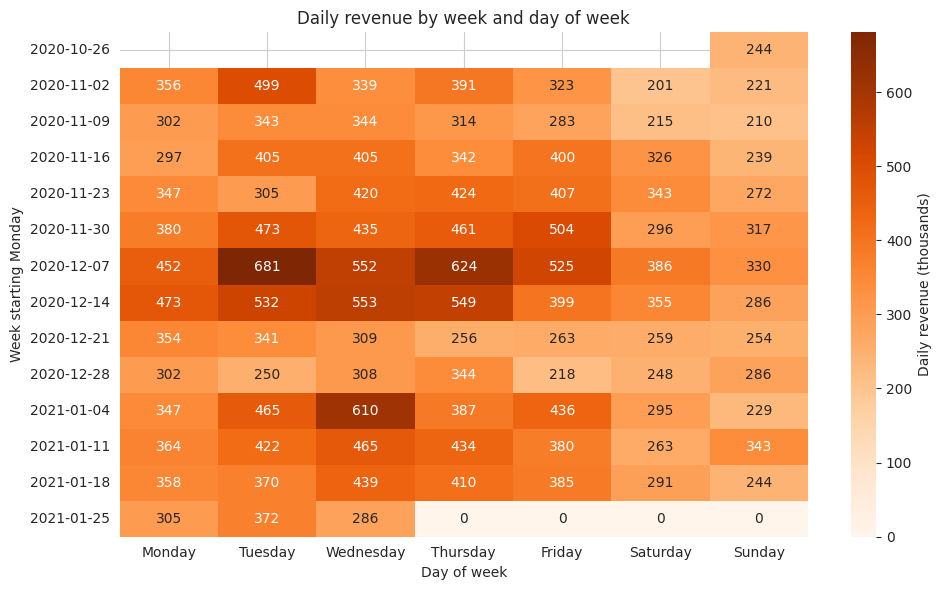

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(weekly_revenue / 1000, annot=True, fmt=".0f", cmap="Oranges",
            yticklabels=weekly_revenue.index.strftime("%Y-%m-%d"),
            cbar_kws={"label": "Daily revenue (thousands)"})
plt.title("Daily revenue by week and day of week")
plt.xlabel("Day of week")
plt.ylabel("Week starting Monday")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Readout.** In all 12 complete weeks from November 2, 2020 to January 24,
2021, average daily estimates are lower on weekends than on weekdays. This is
descriptive evidence of a weekly pattern. The first week is partial and the
last week contains the four unverified zeros; neither is used for that
complete-week observation. Three months do not establish annual seasonality.


### 5.4 Traffic-channel trends


In [ ]:
channel_sales_over_time= (
    df.groupby(["session_date", "channel"], as_index=False)
    .agg(
        sales=("price", "sum")))


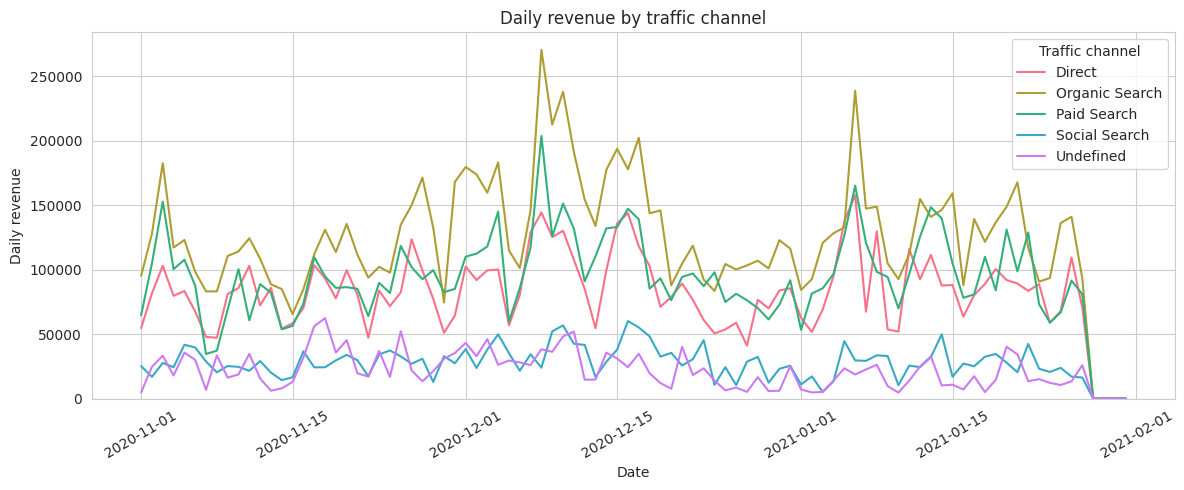

In [ ]:
channel_sales_over_time["session_date"] = pd.to_datetime(channel_sales_over_time["session_date"])
plt.figure(figsize=(12, 5))
sns.lineplot(data=channel_sales_over_time, x="session_date", y="sales", hue="channel", palette="husl")
plt.title("Daily revenue by traffic channel")
plt.xlabel("Date")
plt.ylabel("Daily revenue")
plt.ylim(bottom=0)
plt.legend(title="Traffic channel")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Readout.** Organic Search has the largest observed daily channel peak
(about 270.4 thousand), followed by Paid Search (about 203.6 thousand). The
channel series show several peaks around similar dates. Their final four
zero-valued days reflect absent purchase records and require a coverage check.


### 5.5 Continent trends


In [ ]:
selected_continents = df[
    df["continent"].isin(["Americas", "Asia", "Europe"])
]


In [ ]:
sales_by_continente = (
    selected_continents.groupby(
        ["session_date", "continent"], as_index=False
    )
    .agg(sales=("price", "sum"))
)


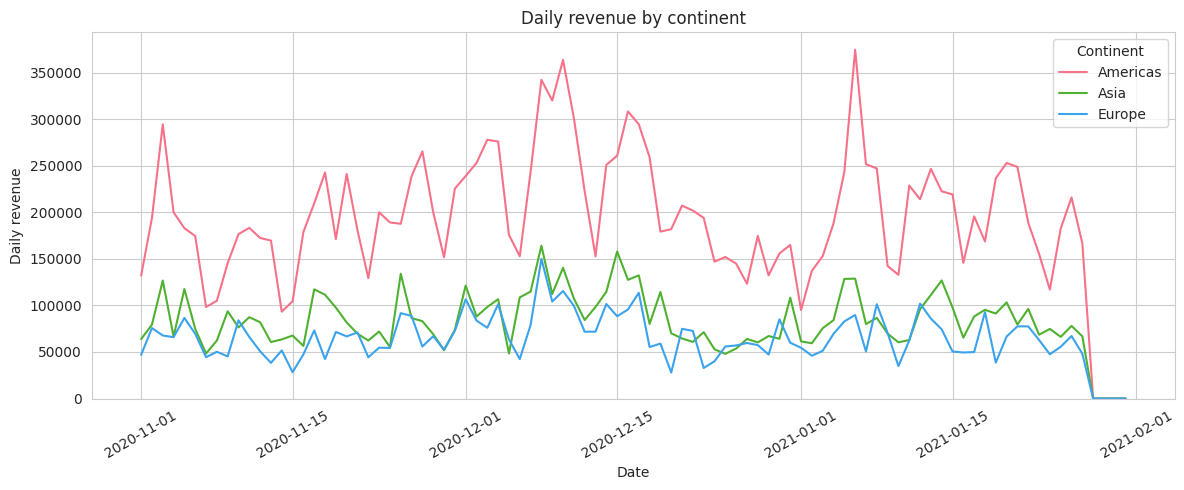

In [ ]:
sales_by_continente["session_date"] = pd.to_datetime(sales_by_continente["session_date"])
plt.figure(figsize=(12, 5))
sns.lineplot(data=sales_by_continente, x="session_date", y="sales", hue="continent", palette="husl")
plt.title("Daily revenue by continent")
plt.xlabel("Date")
plt.ylabel("Daily revenue")
plt.ylim(bottom=0)
plt.legend(title="Continent")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Readout.** The Americas have the highest daily revenue estimate on most
dates and reach an observed peak of about 374.6 thousand. Asia generally
exceeds Europe, although their ordering sometimes changes. The final
zero-valued days have the same unresolved purchase-coverage limitation.


### 5.6 Device-type trends


In [ ]:
device_sales_over_time= (
    df.groupby(["session_date", "device"], as_index=False)
    .agg(
        sales=("price", "sum"))  )


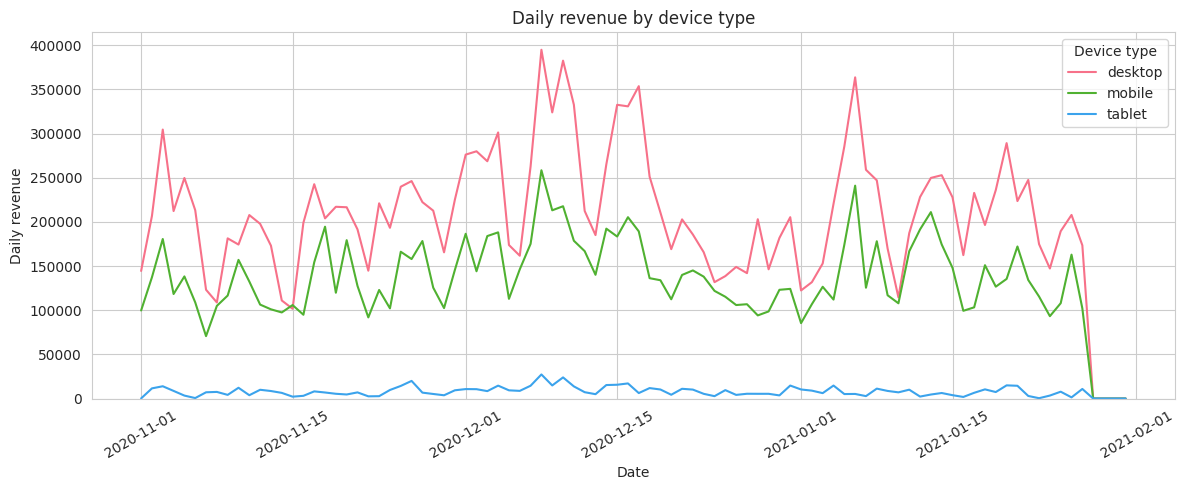

In [ ]:
device_sales_over_time["session_date"] = pd.to_datetime(device_sales_over_time["session_date"])
plt.figure(figsize=(12, 5))
sns.lineplot(data=device_sales_over_time, x="session_date", y="sales", hue="device", palette="husl")
plt.title("Daily revenue by device type")
plt.xlabel("Date")
plt.ylabel("Daily revenue")
plt.ylim(bottom=0)
plt.legend(title="Device type")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Readout.** Desktop leads the daily estimates on most dates, followed by
mobile. Both show pronounced fluctuations around early December and early
January. Tablet contributes much less. The final four zero-valued days remain
a data-coverage qualification.


## 6. Segment comparisons

The pivots compare session volume, the price sum, recorded purchase shares,
and the estimate per session. Each caption states its denominator and scope.

### 6.1 Sessions by known channel and device


In [ ]:
known_channel_sessions = df[df["channel"] != "Undefined"]

pivot_table = pd.pivot_table(
    known_channel_sessions,
    values="ga_session_id",
    index="channel",
    columns="device",
    aggfunc="nunique"
).rename_axis(index="Traffic channel", columns="Device")
display(pivot_table)


Device,desktop,mobile,tablet
Traffic channel,,,
Direct,47825,31745,1812
Organic Search,72622,49014,2789
Paid Search,55167,37034,2140
Social Search,16288,10988,638


**Readout.** After excluding `Undefined`, the pivot covers **328,062
sessions**. Organic Search leads with 124,425 (37.93%), followed by Paid Search
(28.76%), Direct (24.81%), and Social Search (8.51%). Desktop accounts for
58.50%, mobile 39.26%, and tablet 2.25% of these known-channel sessions.

The exclusion removes 21,483 sessions; both the displayed table
and these percentages use the same known-channel scope.


### 6.2 Top categories across top countries


In [ ]:
top_categories = top_category["category"].tolist()
top_countries = top_country["country"].tolist()

selected_sales = df[
    df["category"].isin(top_categories)
    & df["country"].isin(top_countries)
]

pivot_table_2 = pd.pivot_table(
    selected_sales,
    values="price",
    index="category",
    columns="country",
    aggfunc="sum",
    fill_value=0
).reindex(index=top_categories, columns=top_countries, fill_value=0)

display(pivot_table_2.round(2))


country,United States,India,Canada,United Kingdom,France
category,,,,,
Sofas & armchairs,3707144.5,788430.0,692427.5,234812.0,187735.0
Chairs,2619773.8,544309.2,417740.8,188519.4,134029.4
Beds,2213058.0,358319.5,354772.0,133816.0,116414.0
Bookcases & shelving units,1567606.9,364507.4,278981.9,113987.6,73830.0
Cabinets & cupboards,994545.5,191888.0,181802.0,71684.5,59101.5
Outdoor furniture,929245.2,162289.4,185322.8,57002.4,40486.4
Tables & desks,777865.0,186157.5,132678.0,49374.0,42299.0
Chests of drawers & drawer units,382388.0,73111.0,71952.0,36784.0,21544.5
Bar furniture,330805.0,57657.0,51724.0,22103.0,11199.0


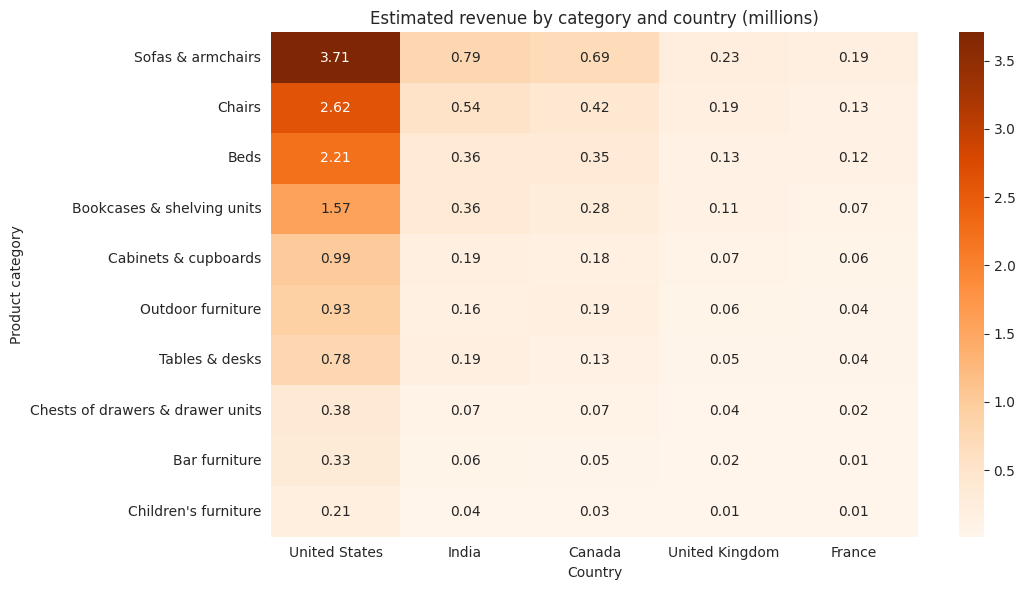

In [ ]:
plt.figure(figsize=(11, 6))
sns.heatmap(pivot_table_2 / 1_000_000, annot=True, fmt=".2f", cmap="Oranges")
plt.title("Estimated revenue by category and country (millions)")
plt.xlabel("Country")
plt.ylabel("Product category")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Readout.** The United States has the largest estimate in every displayed
category. Sofas & armchairs and Chairs are the top two categories in all five
countries; the largest cell is US Sofas & armchairs at about 3.71 million.
Local ordering differs: Bookcases & shelving units exceed Beds in India, and
Outdoor furniture exceeds Cabinets & cupboards in Canada. This comparison
covers the selected global top ten categories and top five countries.


### 6.3 Recorded purchase share by channel and device

The saved extract has one row per unique session. `has_purchase` indicates a
non-null price. Its group mean is the recorded purchase share. The separate
`session_revenue` field treats unmatched purchases as zero only for this
descriptive per-session estimate; source nulls are retained in `df`.


In [ ]:
session_data = df.copy()

session_data["has_purchase"] = session_data["price"].notna()
session_data["session_revenue"] = session_data["price"].fillna(0)


In [ ]:
pivot_table_3 = pd.pivot_table(
    session_data[session_data["channel"] != "Undefined"],
    values="has_purchase",
    index="channel",
    columns="device",
    aggfunc="mean"
) * 100

display(pivot_table_3.round(2))


device,desktop,mobile,tablet
channel,,,
Direct,9.73,9.40,8.83
Organic Search,9.65,9.50,9.14
Paid Search,9.54,9.65,9.67
Social Search,9.79,9.69,8.93


**Readout.** Recorded purchase shares range from 8.83% to 9.79% across the
displayed channel–device groups. Social Search leads desktop (9.79%) and mobile
(9.69%); Paid Search leads tablet (9.67%). Organic Search leads session volume
but not this share in any device group. These 92-day rates describe matched
purchase records and retain the final-days coverage qualification.


### 6.4 Estimate per session by continent and device


In [ ]:
pivot_table_4 = pd.pivot_table(
    session_data[session_data["continent"] != "(not set)"],
    values="session_revenue",
    index="continent",
    columns="device",
    aggfunc="mean"
)

display(pivot_table_4.round(2))


device,desktop,mobile,tablet
continent,,,
Africa,90.87,91.90,103.13
Americas,92.88,89.35,90.69
Asia,90.44,92.45,100.29
Europe,91.63,90.59,86.88
Oceania,111.42,79.46,82.93


**Readout.** The largest displayed estimate per session is Oceania desktop
(111.42), and the smallest is Oceania mobile (79.46). Tablet leads within
Africa (103.13) and Asia (100.29); desktop leads in the Americas, Europe, and
Oceania. Group session counts should be considered alongside these averages.
The measure uses all sessions in each group and the full observation window.


## 7. Statistical relationships

The questions below concern linear co-movement between numerical daily
metrics, so Pearson's r is used to describe the direction and strength of
association. Scatterplots help assess the shape of each relationship and
the influence of unusual dates.

Daily observations are aligned by date. The primary analysis window is
November 1, 2020-January 27, 2021 (**88 days**). The full **92-day** plots
and Pearson tables are retained as a comparison of observation windows;
the final four dates contain sessions but no recorded purchases.

The ordinary Pearson p-values shown in the individual sections are
reference calculations that assume independent daily observations.
The common diagnostic and HAC results after section 7.4 are used for
the final significance conclusions for sections 7.1-7.4.


### 7.1 Sessions and the revenue estimate

**Question.** Do days with more unique sessions also have a higher revenue
estimate? The full-window scatterplot is descriptive; the primary
88-day coefficient and the 92-day comparison are reported below.


In [ ]:
daily_metrics  = (
df.groupby("session_date", as_index=False, dropna=False).agg(
    total_revenue=("price", "sum"),
    sessions=("ga_session_id", "nunique") ))


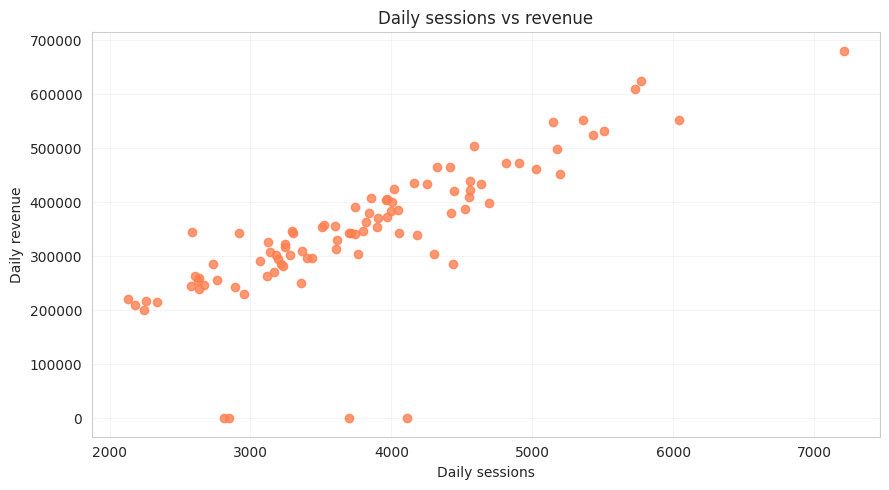

In [ ]:
plt.figure(figsize=(9, 5))
plt.scatter(daily_metrics["sessions"], daily_metrics["total_revenue"], color="coral", alpha=0.8)
plt.title("Daily sessions vs revenue")
plt.xlabel("Daily sessions")
plt.ylabel("Daily revenue")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Window comparison.** Compare the full 92-day series with the 88-day
series through January 27. The ordinary p-values below do not account for
time dependence. The final HAC significance check is shown after section 7.4.


In [ ]:
correlation_data = daily_metrics[
    pd.to_datetime(daily_metrics["session_date"]) <= "2021-01-27"
]


In [ ]:
from scipy.stats import pearsonr

daily_results = []
for period, data in [
    ("Through Jan 27", correlation_data),
    ("Full session window", daily_metrics)
]:
    r, p_value = pearsonr(data["sessions"], data["total_revenue"])
    daily_results.append({
        "Period": period,
        "Days": len(data),
        "Pearson r": r,
        "Unadjusted p-value": p_value
    })

daily_results = pd.DataFrame(daily_results)
display(daily_results)


,Period,Days,Pearson r,Unadjusted p-value
0,Through Jan 27,88,0.931315,1.739462e-39
1,Full session window,92,0.791081,6.483532e-21


**Readout.** Through January 27, daily sessions and the revenue estimate
have a strong positive linear association (**r = 0.931**). Including
January 28-31 reduces the coefficient to **0.791**. Its measured strength
is therefore sensitive to the four dates without recorded purchases.

The ordinary p-values above are reference results. The time-dependence
diagnostic and final significance check for this relationship appear
after section 7.4.


### 7.2 Associations across the top three continents

**Question.** Do daily revenue estimates move together across the three
continents with the highest total estimates? Pearson's r describes the
linear association for each pair. The full-window plots and tables are
compared with the primary 88-day results.


In [ ]:
continent_summary = (
    df.groupby("continent", as_index=False)
    .agg(total_revenue=("price", "sum"))
)

top_continent = continent_summary.nlargest(3, "total_revenue")

continent_daily_sales = (
    df[df["continent"].isin(top_continent["continent"])]
    .groupby(["session_date", "continent"], as_index=False)
    .agg(total_revenue=("price", "sum"))
)

display(top_continent)
display(continent_daily_sales)


,continent,total_revenue
2,Americas,17665280.0
3,Asia,7601298.3
4,Europe,5934624.2


,session_date,continent,total_revenue
0,2020-11-01,Americas,132002.5
1,2020-11-01,Asia,63823.0
2,2020-11-01,Europe,46908.0
3,2020-11-02,Americas,193861.0
4,2020-11-02,Asia,79370.0
...,...,...,...
271,2021-01-30,Asia,0.0
272,2021-01-30,Europe,0.0
273,2021-01-31,Americas,0.0
274,2021-01-31,Asia,0.0


In [ ]:
continent_pivot = continent_daily_sales.pivot(
    index="session_date", columns="continent", values="total_revenue"
)
pairs = [("Americas", "Asia"), ("Americas", "Europe"), ("Asia", "Europe")]


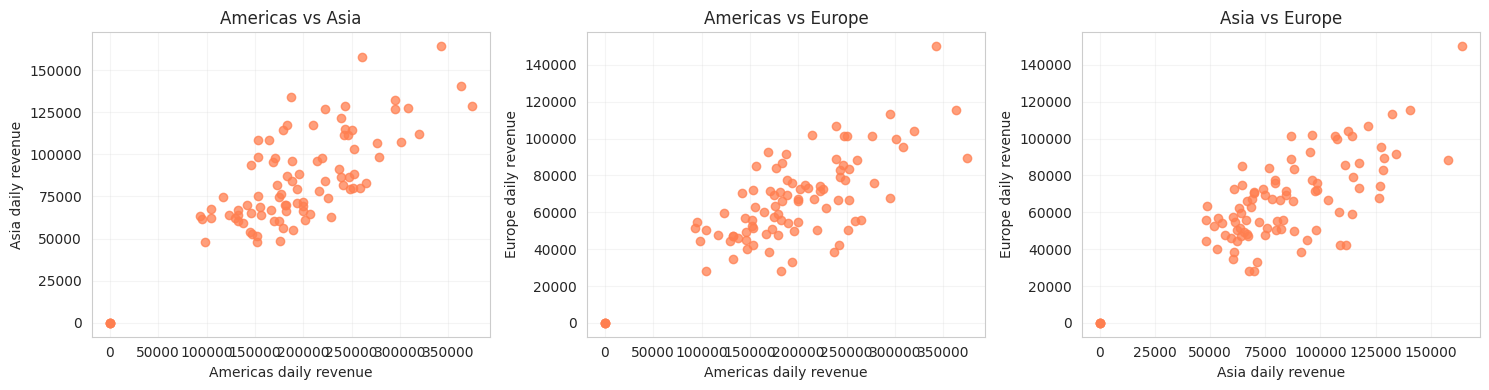

In [ ]:
plt.figure(figsize=(15, 4))
for i, (first, second) in enumerate(pairs, 1):
    plt.subplot(1, 3, i)
    plt.scatter(continent_pivot[first], continent_pivot[second], color="coral", alpha=0.75)
    plt.title(f"{first} vs {second}")
    plt.xlabel(f"{first} daily revenue")
    plt.ylabel(f"{second} daily revenue")
    plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Conventional Pearson test: full session window, 92 days.**
These reference p-values do not account for dependence between dates.


In [ ]:
from scipy.stats import pearsonr

pairs = [
    ("Americas", "Asia"),
    ("Americas", "Europe"),
    ("Asia", "Europe")
]

results = []

for first, second in pairs:
    r, p_value = pearsonr(
        continent_pivot[first],
        continent_pivot[second]
    )
    results.append({
        "Comparison": f"{first} vs {second}",
        "Pearson r": r,
        "Unadjusted p-value": p_value
    })

continent_results_full = pd.DataFrame(results)
continent_results_full["Bonferroni p-value"] = (
    continent_results_full["Unadjusted p-value"] * len(pairs)
).clip(upper=1)

display(continent_results_full)


,Comparison,Pearson r,Unadjusted p-value,Bonferroni p-value
0,Americas vs Asia,0.792025,5.409189e-21,1.622757e-20
1,Americas vs Europe,0.770586,2.671449e-19,8.014348e-19
2,Asia vs Europe,0.768427,3.864946e-19,1.159484e-18


**Conventional Pearson test: primary window, 88 days through January 27.**
The final significance conclusions use the HAC results after section 7.4.


In [ ]:
continent_pivot_check = continent_pivot[
    pd.to_datetime(continent_pivot.index) <= "2021-01-27"
]


In [ ]:
from scipy.stats import pearsonr

pairs = [
    ("Americas", "Asia"),
    ("Americas", "Europe"),
    ("Asia", "Europe")
]

results = []

for first, second in pairs:
    r, p_value = pearsonr(
        continent_pivot_check[first],
        continent_pivot_check[second]
    )
    results.append({
        "Comparison": f"{first} vs {second}",
        "Pearson r": r,
        "Unadjusted p-value": p_value
    })

continent_results_check = pd.DataFrame(results)
continent_results_check["Bonferroni p-value"] = (
    continent_results_check["Unadjusted p-value"] * len(pairs)
).clip(upper=1)

display(continent_results_check)


,Comparison,Pearson r,Unadjusted p-value,Bonferroni p-value
0,Americas vs Asia,0.692273,8.004063e-14,2.401219e-13
1,Americas vs Europe,0.669527,9.911408e-13,2.973422e-12
2,Asia vs Europe,0.667786,1.190893e-12,3.572679e-12


**Readout.** The 88-day coefficients are **0.692** for Americas-Asia,
**0.670** for Americas-Europe, and **0.668** for Asia-Europe. All are
positive. Including the final four dates raises them to **0.792**,
**0.771**, and **0.768**.

The tables above show conventional Pearson tests. The final significance
conclusions below use HAC standard errors and a Bonferroni correction
within these three continent comparisons.


### 7.3 Associations across traffic channels

**Question.** Do daily revenue estimates move together across the four
known traffic channels? Pearson's r describes the pairwise linear
associations. Undefined traffic is excluded from this channel comparison.


In [ ]:
channel_sales_over_time = (
    df.groupby(["session_date", "channel"], as_index=False)
    .agg(sales=("price", "sum"))
)

channel_pivot = channel_sales_over_time[
    channel_sales_over_time["channel"] != "Undefined"
].pivot(
    index="session_date",
    columns="channel",
    values="sales"
)

display(channel_pivot)


channel,Direct,Organic Search,Paid Search,Social Search
session_date,,,,
2020-11-01,54669.5,95112.0,64688.0,25078.0
2020-11-02,81561.5,127746.5,104780.8,16843.0
2020-11-03,102909.5,182521.9,152641.3,27652.5
2020-11-04,79683.6,117067.1,100332.0,24257.4
2020-11-05,83367.6,122938.4,107648.0,41693.2
...,...,...,...,...
2021-01-27,70423.1,92921.1,80869.5,16282.0
2021-01-28,0.0,0.0,0.0,0.0
2021-01-29,0.0,0.0,0.0,0.0


In [ ]:
from itertools import combinations
channel_pairs = list(combinations(channel_pivot.columns, 2))


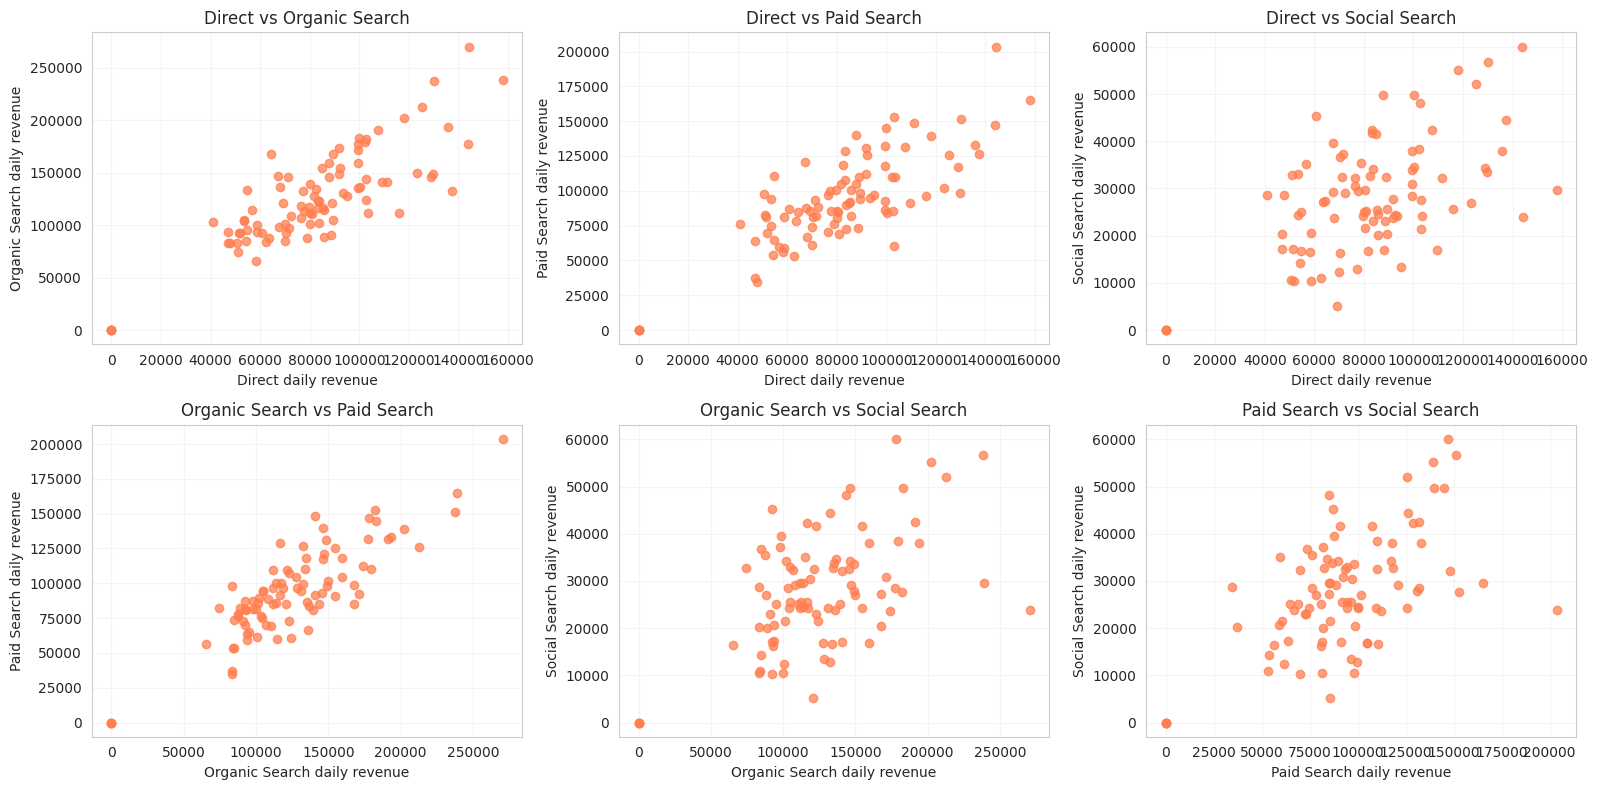

In [ ]:
plt.figure(figsize=(16, 8))
for i, (first, second) in enumerate(channel_pairs, 1):
    plt.subplot(2, 3, i)
    plt.scatter(channel_pivot[first], channel_pivot[second], color="coral", alpha=0.75)
    plt.title(f"{first} vs {second}")
    plt.xlabel(f"{first} daily revenue")
    plt.ylabel(f"{second} daily revenue")
    plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Conventional Pearson test: full session window, 92 days.**
These reference p-values do not account for dependence between dates.


In [ ]:
from itertools import combinations
from scipy.stats import pearsonr

channel_pairs = list(combinations(channel_pivot.columns, 2))

results = []

for first, second in channel_pairs:
    r, p_value = pearsonr(
        channel_pivot[first],
        channel_pivot[second]
    )
    results.append({
        "Comparison": f"{first} vs {second}",
        "Pearson r": r,
        "Unadjusted p-value": p_value
    })

channel_results_full = pd.DataFrame(results)
channel_results_full["Bonferroni p-value"] = (
    channel_results_full["Unadjusted p-value"] * len(channel_pairs)
).clip(upper=1)

display(channel_results_full)


,Comparison,Pearson r,Unadjusted p-value,Bonferroni p-value
0,Direct vs Organic Search,0.837833,2.190420e-25,1.314252e-24
1,Direct vs Paid Search,0.814072,5.896435e-23,3.537861e-22
2,Direct vs Social Search,0.604060,1.831889e-10,1.099134e-09
3,Organic Search vs Paid Search,0.870086,2.142003e-29,1.285202e-28
4,Organic Search vs Social Search,0.583117,1.066192e-09,6.397155e-09
5,Paid Search vs Social Search,0.596428,3.532284e-10,2.119371e-09


**Conventional Pearson test: primary window, 88 days through January 27.**
The final significance conclusions use the HAC results after section 7.4.


In [ ]:
channel_pivot_check = channel_pivot[
    pd.to_datetime(channel_pivot.index) <= "2021-01-27"
]


In [ ]:
from itertools import combinations
from scipy.stats import pearsonr

channel_pairs = list(combinations(channel_pivot.columns, 2))

results = []

for first, second in channel_pairs:
    r, p_value = pearsonr(
        channel_pivot_check[first],
        channel_pivot_check[second]
    )
    results.append({
        "Comparison": f"{first} vs {second}",
        "Pearson r": r,
        "Unadjusted p-value": p_value
    })

channel_results_check = pd.DataFrame(results)
channel_results_check["Bonferroni p-value"] = (
    channel_results_check["Unadjusted p-value"] * len(channel_pairs)
).clip(upper=1)

display(channel_results_check)


,Comparison,Pearson r,Unadjusted p-value,Bonferroni p-value
0,Direct vs Organic Search,0.759938,9.107881e-18,5.464729e-17
1,Direct vs Paid Search,0.724343,1.512880e-15,9.077279e-15
2,Direct vs Social Search,0.461895,5.901047e-06,3.540628e-05
3,Organic Search vs Paid Search,0.808234,1.755643e-21,1.053386e-20
4,Organic Search vs Social Search,0.434424,2.347593e-05,1.408556e-04
5,Paid Search vs Social Search,0.452287,9.696038e-06,5.817623e-05


**Readout.** Through January 27, the largest channel coefficient is
Organic Search-Paid Search (**r = 0.808**), followed by Direct-Organic
Search (**0.760**) and Direct-Paid Search (**0.724**). Coefficients
involving Social Search are lower (**0.434-0.462**). Including the
final four dates increases every coefficient.

The final significance conclusions below use HAC standard errors and
a Bonferroni correction within these six channel comparisons.


### 7.4 Associations across the top five categories

**Question.** Do daily revenue estimates move together across the five
categories with the highest total estimates? The selected series have
**88 aligned dates**, November 1-January 27, with no missing values.
The heatmap describes their Pearson coefficients.

The first test table below contains conventional Pearson p-values for
reference. The diagnostic and HAC table that follow provide the basis
for the final significance conclusions.


In [ ]:
top_5_categories = (
    df.groupby("category", as_index=False)
    .agg(total_revenue=("price", "sum"))
    .sort_values("total_revenue", ascending=False)
    .head(5)
)

category_daily_sales = (
    df[df["category"].isin(top_5_categories["category"])]
    .groupby(["session_date", "category"], as_index=False)
    .agg(total_revenue=("price", "sum"))
)


In [ ]:
category_pivot = category_daily_sales.pivot(
    index="session_date",
    columns="category",
    values="total_revenue"
)


In [ ]:
category_corr = category_pivot.corr(method="pearson")


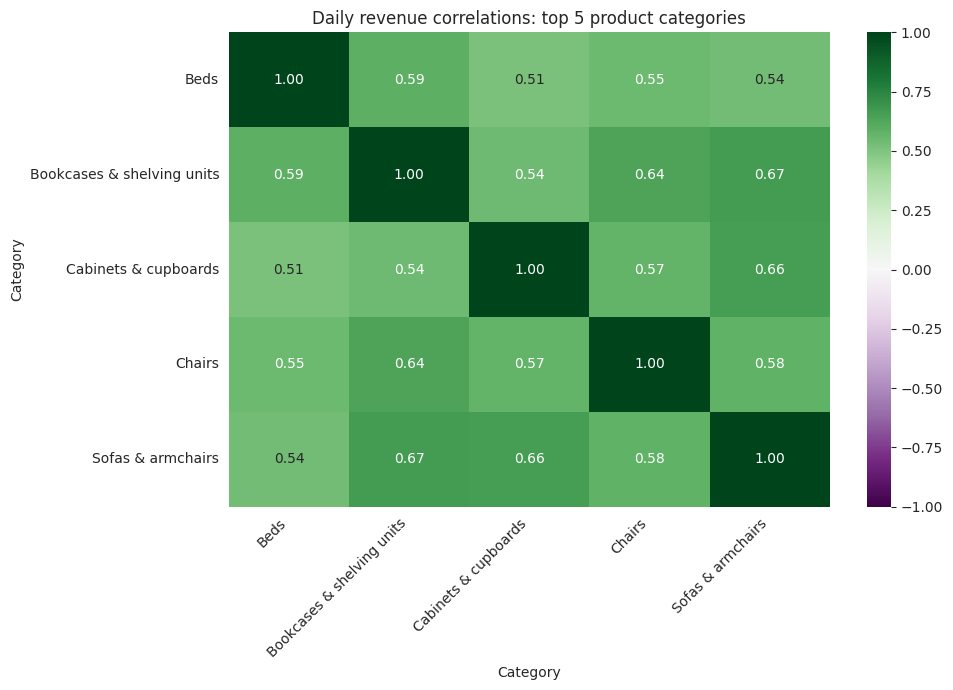

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(category_corr, annot=True, fmt=".2f", cmap="PRGn", vmin=-1, vmax=1)
plt.title("Daily revenue correlations: top 5 product categories")
plt.xlabel("Category")
plt.ylabel("Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
from itertools import combinations
from scipy.stats import pearsonr

category_pairs = list(combinations(category_pivot.columns, 2))

results = []

for first, second in category_pairs:
    r, p_value = pearsonr(
        category_pivot[first],
        category_pivot[second]
    )
    results.append({
        "Comparison": f"{first} vs {second}",
        "Pearson r": r,
        "Unadjusted p-value": p_value
    })

category_results = pd.DataFrame(results)
category_results["Bonferroni p-value"] = (
    category_results["Unadjusted p-value"] * len(category_pairs)
).clip(upper=1)

display(category_results)


,Comparison,Pearson r,Unadjusted p-value,Bonferroni p-value
0,Beds vs Bookcases & shelving units,0.592913,1.154998e-09,1.154998e-08
1,Beds vs Cabinets & cupboards,0.514609,2.910930e-07,2.910930e-06
2,Beds vs Chairs,0.554500,2.079183e-08,2.079183e-07
3,Beds vs Sofas & armchairs,0.535378,7.687333e-08,7.687333e-07
4,Bookcases & shelving units vs Cabinets & cupbo...,0.539428,5.867225e-08,5.867225e-07
5,Bookcases & shelving units vs Chairs,0.637090,2.504550e-11,2.504550e-10
6,Bookcases & shelving units vs Sofas & armchairs,0.666194,1.406972e-12,1.406972e-11
7,Cabinets & cupboards vs Chairs,0.572870,5.465903e-09,5.465903e-08
8,Cabinets & cupboards vs Sofas & armchairs,0.657563,3.415056e-12,3.415056e-11
9,Chairs vs Sofas & armchairs,0.578248,3.638833e-09,3.638833e-08


**Time-dependence check for sections 7.1-7.4.** The following cell checks
each primary 88-day series against its values one day and seven days
earlier. Positive autocorrelation is visible across the examined series:
lag-1 coefficients range from **0.309 to 0.719**.

These are initial diagnostics, not a complete test of independence.
The observed dependence means that the ordinary Pearson p-values should
not be used alone for the final significance conclusions.


In [ ]:
checks = {
    "Sessions and revenue": correlation_data[
        ["sessions", "total_revenue"]
    ],
    "Continents": continent_pivot_check,
    "Traffic channels": channel_pivot_check,
    "Categories": category_pivot
}

for name, data in checks.items():
    print(name)
    display(pd.DataFrame({
        "Lag 1": data.corrwith(data.shift(1)),
        "Lag 7": data.corrwith(data.shift(7))
    }).round(3))

Sessions and revenue


,Lag 1,Lag 7
sessions,0.719,0.606
total_revenue,0.625,0.515


Continents


,Lag 1,Lag 7
continent,,
Americas,0.599,0.491
Asia,0.408,0.250
Europe,0.351,0.257


Traffic channels


,Lag 1,Lag 7
channel,,
Direct,0.430,0.359
Organic Search,0.571,0.451
Paid Search,0.497,0.433
Social Search,0.331,0.192


Categories


,Lag 1,Lag 7
category,,
Beds,0.373,0.344
Bookcases & shelving units,0.487,0.340
Cabinets & cupboards,0.452,0.489
Chairs,0.390,0.302
Sofas & armchairs,0.309,0.317


**Method selection for the final significance checks.** Pearson's r
remains the descriptive measure of linear association. For each pair,
a regression slope test uses Newey-West (HAC) standard errors with
**7 lags**, covering dependence up to one week, and a t reference
distribution. This is an approximate test of a zero linear slope,
rather than the ordinary p-value returned by Pearson's test.

Bonferroni correction is applied separately within each question:
**1** session-revenue comparison, **3** continent comparisons,
**6** channel comparisons, and **10** category comparisons.
Compare the final Bonferroni p-values with **0.05**.

HAC does not remove shared trends or seasonality. The results describe
co-movement within this observation window and do not establish causes.


In [ ]:
import statsmodels.api as sm
from itertools import combinations

hac_rows = []

for group, data in checks.items():
    pairs = list(combinations(data.columns, 2))

    for first, second in pairs:
        pair = data[[first, second]].sort_index().dropna().astype(float)

        model = sm.OLS(pair[second], sm.add_constant(pair[first]))
        result = model.fit(
            cov_type="HAC", cov_kwds={"maxlags": 7}, use_t=True
        )
        p_hac = result.pvalues[first]

        hac_rows.append({
            "Group": group,
            "Comparison": f"{first} vs {second}",
            "Pearson r": pair[first].corr(pair[second]),
            "HAC p-value": p_hac,
            "Bonferroni p-value": min(p_hac * len(pairs), 1)
        })

hac_results = pd.DataFrame(hac_rows)
display(hac_results)

,Group,Comparison,Pearson r,HAC p-value,Bonferroni p-value
0,Sessions and revenue,sessions vs total_revenue,0.931315,2.091987e-46,2.091987e-46
1,Continents,Americas vs Asia,0.692273,1.132781e-22,3.398343e-22
2,Continents,Americas vs Europe,0.669527,1.836964e-08,5.510893e-08
3,Continents,Asia vs Europe,0.667786,2.419956e-11,7.259868e-11
4,Traffic channels,Direct vs Organic Search,0.759938,6.445964e-12,3.867579e-11
5,Traffic channels,Direct vs Paid Search,0.724343,1.238706e-11,7.432238e-11
6,Traffic channels,Direct vs Social Search,0.461895,7.074614e-05,4.244768e-04
7,Traffic channels,Organic Search vs Paid Search,0.808234,6.251665e-22,3.750999e-21
8,Traffic channels,Organic Search vs Social Search,0.434424,4.551061e-05,2.730637e-04
9,Traffic channels,Paid Search vs Social Search,0.452287,1.400776e-05,8.404654e-05


**Conclusions for sections 7.1-7.4.** These conclusions use the **88-day
window**, HAC standard errors with **7 lags**, and Bonferroni correction
within each question.

- **7.1 Sessions and revenue.** The positive association is strong
  (**r = 0.931**) and the regression slope is statistically significant
  under the selected HAC specification (**p < 0.001**).
- **7.2 Continents.** All three continent pairs have positive coefficients
  (**r = 0.668-0.692**) and pass the adjusted 0.05 threshold
  (**all adjusted p < 0.001**).
- **7.3 Traffic channels.** All six channel pairs have positive
  coefficients (**r = 0.434-0.808**) and pass the adjusted threshold
  (**all adjusted p < 0.001**). Organic Search-Paid Search has the
  largest coefficient.
- **7.4 Categories.** All ten category coefficients are positive
  (**r = 0.515-0.666**). **Nine of ten pairs** pass the adjusted threshold.
  Beds-Cabinets & cupboards does not (**adjusted p approximately 0.100**).
  This p-value belongs to the HAC table, not the conventional Pearson table.

The statistical conclusions are conditional on the selected time-series
specification. Shared seasonal patterns or trends may help explain
these associations; the results do not establish causal effects.


### 7.5 Email verification and recorded purchasing

The additional analyses below use the 88-day window. For verification, the
unit is a unique registered account, and the outcome is having at least one
recorded purchase. The contingency test uses counts, with Fisher's exact test
as the fallback when expected frequencies are small.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, fisher_exact, pearsonr

analysis_data = df[
    pd.to_datetime(df["session_date"]).between("2020-11-01", "2021-01-27")
].copy()

analysis_data["has_purchase"] = analysis_data["price"].notna()


In [ ]:
user_data = (
    analysis_data.dropna(subset=["account_id", "is_verified"])
    .groupby("account_id", as_index=False)
    .agg(
        is_verified=("is_verified", "first"),
        has_purchase=("has_purchase", "max")
    )
)

purchase_table = pd.crosstab(
    user_data["is_verified"],
    user_data["has_purchase"]
)

chi2, verification_p, _, expected = chi2_contingency(
    purchase_table, correction=False
)

test_name = "Chi-square"

if expected.min() < 5:
    _, verification_p = fisher_exact(purchase_table)
    test_name = "Fisher exact"

purchase_rates = (
    user_data.groupby("is_verified")["has_purchase"]
    .mean().mul(100)
    .rename(index={0: "Unverified", 1: "Verified"})
)

display(purchase_table)
display(purchase_rates.rename("Purchase rate (%)"))
print("Test:", test_name)
print("Unadjusted p-value:", verification_p)


has_purchase,False,True
is_verified,,
0,7117,792
1,18047,1989


,Purchase rate (%)
is_verified,
Unverified,10.013908
Verified,9.927131


Test: Chi-square
Unadjusted p-value: 0.8272035474591852


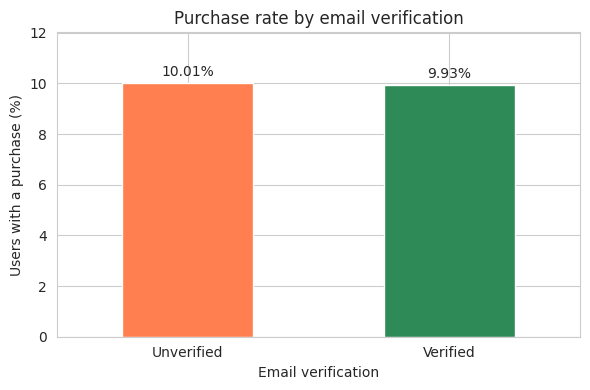

In [ ]:
ax = purchase_rates.plot.bar(
    color=["coral", "seagreen"], rot=0, figsize=(6, 4),
    title="Purchase rate by email verification", ylabel="Users with a purchase (%)")
ax.set_xlabel("Email verification")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()


**Readout.** Among unique registered users in the 88-day analysis window,
10.01% of unverified users and 9.93% of verified users have a recorded purchase:
a difference of approximately 0.08 percentage points. The chi-square test
does not detect an association at the additional-tests Bonferroni threshold
of 0.025 (**p = 0.827**). The comparison concerns recorded status and does not
establish an effect of verification.


### 7.6 Purchasing-session volume and average product price

The unit is a day. Product price is averaged across recorded purchases; no
order-value or quantity assumption is required for this mean.


In [ ]:
daily_price_volume = (
    analysis_data[analysis_data["has_purchase"]]
    .groupby("session_date", as_index=False)
    .agg(
        purchasing_sessions=("ga_session_id", "nunique"),
        average_product_price=("price", "mean")
    )
)

r, price_volume_p = pearsonr(
    daily_price_volume["purchasing_sessions"],
    daily_price_volume["average_product_price"]
)

print("Days:", len(daily_price_volume))
print("Pearson r:", r)
print("Unadjusted p-value:", price_volume_p)


Days: 88
Pearson r: 0.11582024744554015
Unadjusted p-value: 0.28256438015876556


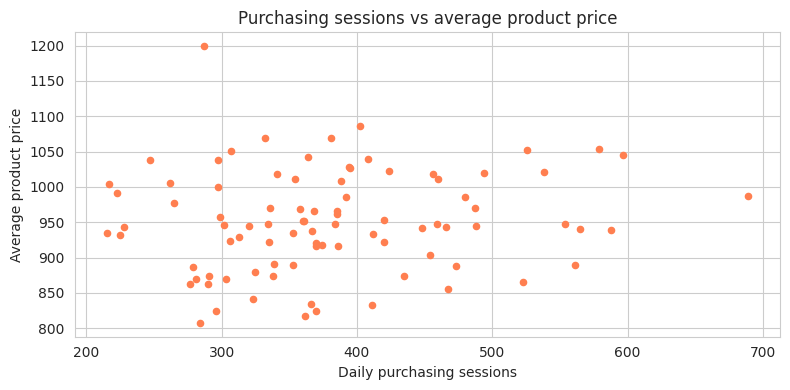

In [ ]:
daily_price_volume.plot.scatter(
    x="purchasing_sessions", y="average_product_price", color="coral", figsize=(8, 4),
    title="Purchasing sessions vs average product price",
    xlabel="Daily purchasing sessions", ylabel="Average product price")
plt.tight_layout()
plt.show()


**Readout.** Across 88 days, purchasing-session volume and average purchased
product price have a very weak positive linear correlation (**r = 0.116**).
The conventional Pearson test does not detect a linear association
(**p = 0.283**; additional-tests threshold 0.025). This is not evidence that
every possible relationship is absent. Possible temporal dependence is not
accounted for in this test.


## 8. Statistical comparison of groups

This section compares daily revenue estimates, session counts, traffic shares,
and purchasing measures across groups.


### 8.1 Daily revenue estimates per session by registration status



In [ ]:
comparison_data = df.copy()
comparison_data["session_date"] = pd.to_datetime(comparison_data["session_date"])
comparison_data = comparison_data[comparison_data["session_date"] <= "2021-01-27"]

registered = comparison_data[comparison_data["account_id"].notna()]
unregistered = comparison_data[comparison_data["account_id"].isna()]

print("Registered sessions:", len(registered))
print("Unregistered sessions:", len(unregistered))

Registered sessions: 27945
Unregistered sessions: 308131


In [ ]:
registered_sales = registered.groupby("session_date").agg(
    total_revenue=("price", "sum"),
    sessions=("ga_session_id", "nunique")
)

unregistered_sales = unregistered.groupby("session_date").agg(
    total_revenue=("price", "sum"),
    sessions=("ga_session_id", "nunique")
)


In [ ]:
print(registered_sales.shape)
print(unregistered_sales.shape)

(88, 2)
(88, 2)


In [ ]:
registered_sample = (
    registered_sales["total_revenue"] / registered_sales["sessions"]
)
unregistered_sample = (
    unregistered_sales["total_revenue"] / unregistered_sales["sessions"]
)

samples = pd.DataFrame({
    "Registered": registered_sample,
    "Unregistered": unregistered_sample
})

summary = samples.describe()
display(summary.round(2))

,Registered,Unregistered
count,88.00,88.00
mean,92.74,95.37
std,26.50,9.61
min,42.07,65.26
25%,73.65,89.90
50%,90.84,94.85
75%,108.42,100.89
max,201.77,126.90


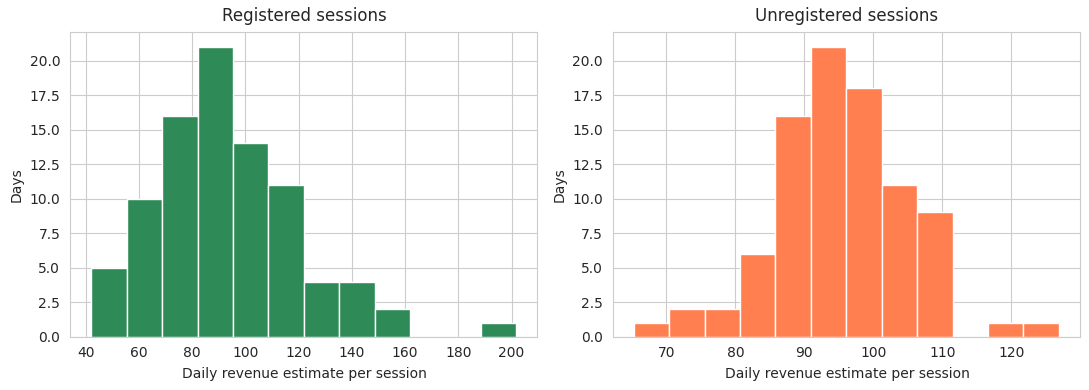

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(registered_sample, bins=12, color="seagreen", edgecolor="white")
axes[0].set(
    title="Registered sessions",
    xlabel="Daily revenue estimate per session", ylabel="Days"
)

axes[1].hist(unregistered_sample, bins=12, color="coral", edgecolor="white")
axes[1].set(
    title="Unregistered sessions",
    xlabel="Daily revenue estimate per session", ylabel="Days"
)

plt.tight_layout()
plt.show()


**Distribution readout.** After normalization, the mean daily revenue
estimate per session is **92.74** for registered sessions and **95.37**
for unregistered sessions. Their medians are **90.84** and **94.85**.

The registered-session metric varies more across dates: standard
deviation **26.50**, compared with **9.61** for unregistered sessions.
The panels use separate x-axis scales. The next plot shows paired
daily differences, which include both negative and positive values.


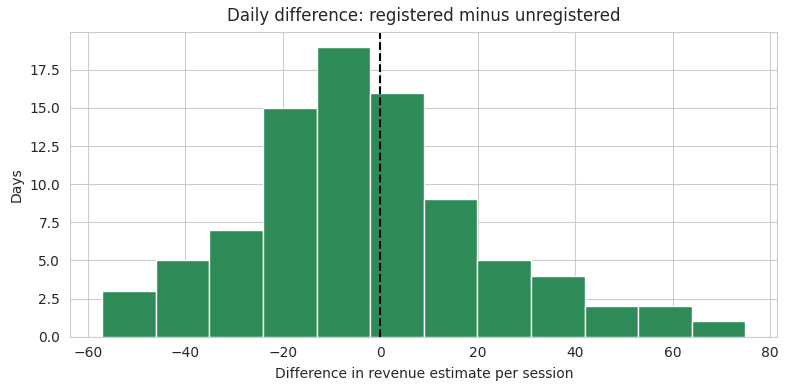

In [ ]:
differences = registered_sample - unregistered_sample

plt.figure(figsize=(8, 4))
plt.hist(differences, bins=12, color="seagreen", edgecolor="white")
plt.axvline(0, color="black", linestyle="--")
plt.title("Daily difference: registered minus unregistered")
plt.xlabel("Difference in revenue estimate per session")
plt.ylabel("Days")
plt.tight_layout()
plt.show()


In [ ]:
from scipy.stats import shapiro

statistic, normality_p = shapiro(differences)

print("Shapiro-Wilk p-value:", normality_p)
print("Lag-1 correlation:", differences.autocorr(lag=1))
print("Lag-7 correlation:", differences.autocorr(lag=7))
print("Mean daily difference:", differences.mean())

Shapiro-Wilk p-value: 0.11402977294704192
Lag-1 correlation: -0.035741791482563796
Lag-7 correlation: 0.06615349341323935
Mean daily difference: -2.6352213101203605


**Test choice.** Normality of the normalized daily differences is not
rejected (**Shapiro-Wilk p = 0.114**). Autocorrelations at lags 1 and 7
are close to zero (**-0.036** and **0.066**). These checks do not prove
normality or independence; independence between dates remains an assumption.

A **two-sided paired t-test** compares the mean daily revenue estimate
per session between the two registration groups. The observations are
paired because both groups are measured on the same dates.
The significance threshold for this primary comparison is **0.05**.


In [ ]:
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(
    samples["Registered"],
    samples["Unregistered"]
)

print("Paired t-statistic:", t_stat)
print("Paired t-test p-value:", p_value)

Paired t-statistic: -0.9674984453830074
Paired t-test p-value: 0.33597681991038897


**Readout.** Across 88 paired dates, mean daily revenue estimates per
session are **92.74** for registered sessions and **95.37** for
unregistered sessions. The mean registered-minus-unregistered
difference is **-2.64**.

The paired t-test does not detect a statistically significant difference
at the 0.05 level (**t(87) = -0.967, p = 0.336**). The comparison concerns
equally weighted daily estimates per session, not total group revenue
or average spending per user. These results do not establish equivalence
between the groups or a causal effect of registration.


### 8.2 Session counts across traffic channels

**Question.** Are sessions distributed equally across the four known channels?

Count unique session IDs over the full session window and exclude `Undefined`.
**H₀:** each known channel has the same session share (**25%**).
Equal shares are the chosen reference distribution for this test.

In [ ]:
channel_data = df[df["channel"] != "Undefined"]

channel_sessions = (
    channel_data.groupby("channel")["ga_session_id"].nunique()
)

display(channel_sessions)

,ga_session_id
channel,
Direct,81382
Organic Search,124425
Paid Search,94341
Social Search,27914


In [ ]:
from scipy.stats import chisquare

statistic, p_value = chisquare(channel_sessions)

print("Chi-square statistic:", statistic)
print("p-value:", p_value)

Chi-square statistic: 59474.82201535076
p-value: 0.0


**Readout.** Among 328,062 sessions with a known channel, Organic Search has
the largest count (**124,425; 37.93%**), while Social Search has the smallest
(27,914; 8.51%). The chi-square goodness-of-fit test rejects equal channel
shares (**χ²(3) = 59,474.82; p < 0.001**).

The test concerns the overall distribution. It does not identify which
individual channel pairs differ. The printed p-value of `0.0` reflects
numerical underflow and is reported as `p < 0.001`.


### 8.3 Organic traffic share: Europe vs Americas

**Question.** Does the share of sessions recorded as `Organic Search` differ
between Europe and the Americas?

The numerator is the unique organic-session count; the denominator is the
total unique-session count within each continent. The denominator includes
sessions labelled `Undefined`, so the measure is the recorded organic share
of all sessions. Both continents use the full 92-day window.

Use a two-sided two-proportion z-test. **H₀:** the organic-session shares are
equal. Europe comes first in both input lists, followed by the Americas.

In [ ]:
europe = df[df["continent"] == "Europe"]
americas = df[df["continent"] == "Americas"]

europe_total = europe["ga_session_id"].nunique()
americas_total = americas["ga_session_id"].nunique()

europe_organic = europe[europe["channel"] == "Organic Search"]["ga_session_id"].nunique()
americas_organic = americas[americas["channel"] == "Organic Search"]["ga_session_id"].nunique()

In [ ]:
print("Europe organic share (%):", round(europe_organic / europe_total * 100, 2))
print("Americas organic share (%):", round(americas_organic / americas_total * 100, 2))

Europe organic share (%): 35.61
Americas organic share (%): 35.55


In [ ]:
from statsmodels.stats.proportion import proportions_ztest

organic_counts = [europe_organic, americas_organic]
session_counts = [europe_total, americas_total]

z_stat, p_value = proportions_ztest(organic_counts, session_counts)

print("Z-statistic:", z_stat)
print("p-value:", p_value)

Z-statistic: 0.28951412926103953
p-value: 0.7721879690501752


**Readout.** The recorded organic share is **35.61%** in Europe and **35.55%**
in the Americas, a difference of approximately **0.06 percentage points**.
The two-proportion z-test does not detect a statistically significant
difference (**z = 0.290; p = 0.772**). At the 0.05 significance level, the
equal-share hypothesis is not rejected; the data provide insufficient
evidence to conclude that the shares differ.

### 8.4 Recorded purchase share: desktop vs mobile

**Question.** Does the share of sessions with a recorded purchase differ
between desktop and mobile?

Restrict the data to the 88-day purchase-analysis window and retain one row
per session. `has_purchase` is `True` when a product price is present.
The contingency table contains session counts with and without a purchase.

Use a chi-square independence test. **H₀:** device type and recorded purchasing
are independent. The significance threshold for this additional test is
**0.025**.

In [ ]:
device_data = df.copy()
device_data["session_date"] = pd.to_datetime(device_data["session_date"])
device_data = device_data[device_data["session_date"] <= "2021-01-27"]
device_data = device_data[device_data["device"].isin(["desktop", "mobile"])]
device_data = device_data.drop_duplicates("ga_session_id")

In [ ]:
from scipy.stats import chi2_contingency

device_data["has_purchase"] = device_data["price"].notna()

purchase_table = pd.crosstab(
    device_data["device"], device_data["has_purchase"]
)

chi2_stat, p_purchase, dof, expected = chi2_contingency(purchase_table)

purchase_rates = purchase_table[True] / purchase_table.sum(axis=1) * 100

display(purchase_table)
print("Purchase rate (%):")
display(purchase_rates.round(2))

print("Chi-square p-value:", p_purchase)
print("Minimum expected count:", expected.min())

has_purchase,False,True
device,,
desktop,176875,19702
mobile,118842,13113


Purchase rate (%):


,0
device,
desktop,10.02
mobile,9.94


Chi-square p-value: 0.4288569617805885
Minimum expected count: 13180.156955791217


**Readout.** Recorded purchase rates are **10.02%** for desktop and **9.94%**
for mobile. The chi-square test does not detect an association between
device type and recorded purchasing (**p = 0.429**) at the adjusted
significance level of **0.025**.

The minimum expected cell count is **13,180.16**, comfortably above the
usual guideline of 5 for the chi-square approximation.

### 8.5 Purchased-product prices: desktop vs mobile

**Question.** Do recorded product-price distributions differ between
desktop and mobile purchasing sessions?

Use the same 88-day window and device groups as in section 8.4.
Missing prices are removed to retain purchasing sessions.
**H0:** the price distributions are the same. The significance threshold
is **0.025**, accounting for the two additional device comparisons
in sections 8.4 and 8.5.


In [ ]:
desktop_prices = device_data[device_data["device"] == "desktop"]["price"].dropna()
mobile_prices = device_data[device_data["device"] == "mobile"]["price"].dropna()


,Desktop,Mobile
count,19702.00,13113.00
mean,957.47,944.42
std,1316.64,1315.51
min,3.00,3.00
25%,175.00,165.00
50%,445.00,435.00
75%,1196.00,1155.00
max,9585.00,9585.00


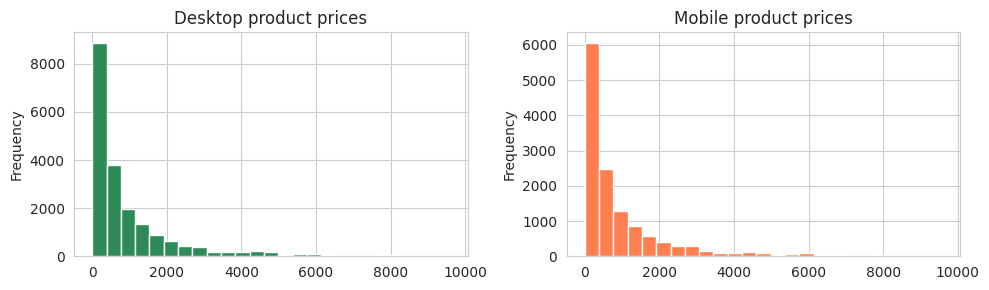

In [ ]:
display(pd.DataFrame({
    "Desktop": desktop_prices.describe(),
    "Mobile": mobile_prices.describe()
}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

desktop_prices.plot.hist(
    ax=axes[0], bins=25, color="seagreen",
    title="Desktop product prices"
)
mobile_prices.plot.hist(
    ax=axes[1], bins=25, color="coral",
    title="Mobile product prices"
)

plt.tight_layout()
plt.show()

**Method selection.** Purchased-product prices are strongly right-skewed in both device groups. Mean prices are 957.47 for desktop and 944.42 for mobile, compared with medians of 445 and 435.

A two-sided Mann–Whitney U test is used to compare price distributions without assuming normality. Purchasing sessions are treated as independent observations. The test is not interpreted as a direct comparison of mean prices.

In [ ]:
from scipy.stats import mannwhitneyu

u_stat, p_price = mannwhitneyu(desktop_prices, mobile_prices)

print("Desktop median price:", desktop_prices.median())
print("Mobile median price:", mobile_prices.median())
print("Mann-Whitney p-value:", p_price)


Desktop median price: 445.0
Mobile median price: 435.0
Mann-Whitney p-value: 0.15860325976935175


**Readout.** Median purchased-product prices are **445** for desktop
and **435** for mobile. The two-sided Mann-Whitney U test does not
detect a statistically significant difference in price distributions
(**p = 0.159; adjusted significance threshold = 0.025**).

The observed median difference is descriptive. The test result does
not establish that the distributions are identical.


## Overall conclusion

The recorded product prices sum to **31.97 million in estimated revenue**.
The analysis highlights sales concentration, the importance of traffic
volume, and the need to compare customer groups using normalized metrics.

- **Markets and products.** The Americas lead the geographic rankings.
  The United States contributes **13.94 million**, or **43.61%** of the
  revenue estimate. Sofas & armchairs, Chairs, and Beds together account
  for **60.85%**, showing concentration in a small number of furniture
  categories.
- **Devices and acquisition.** Desktop contributes **59.00%** of the
  revenue estimate and mobile **38.73%**. Organic Search has the most
  sessions among known traffic channels. Desktop and mobile purchase
  rates are close (**10.02% vs 9.94%**), with no statistically significant
  difference detected (**p = 0.429**). Their purchased-product price
  distributions also do not differ significantly in the test
  (**p = 0.159**).
- **Sales patterns.** Weekend daily estimates are lower than weekday
  estimates in all **12 complete weeks** examined. This supports a
  weekly pattern; three months of data do not establish annual
  seasonality. Daily session volume and the revenue estimate have
  a strong positive association (**r = 0.931**).
- **Relationships between segments.** Positive co-movement also appears
  across continents, traffic channels, and product categories.
  Under the selected HAC specification and Bonferroni correction,
  **9 of 10 category pairs** are statistically significant.
  Beds-Cabinets & cupboards does not meet the adjusted threshold
  (**p approximately 0.100**).
- **Registered accounts.** Among **27,945** represented accounts,
  **71.70%** have a verified email and **16.94%** are unsubscribed.
  The subscription groups show small descriptive differences, but
  tests do not detect differences in buyer share (**p = 0.197**) or
  account-level revenue distributions (**p = 0.228**) at the adjusted
  **0.025** threshold.
- **Revenue per session.** After accounting for different session
  volumes, mean daily revenue estimates per session are **92.74**
  for registered sessions and **95.37** for unregistered sessions.
  The mean paired difference is **-2.64** and is not statistically
  significant (**paired t-test p = 0.336**). The large difference
  between total group revenues therefore does not translate into
  a significant difference in this normalized daily measure.

Performance should be monitored using both totals and per-session
measures, so changes in traffic volume can be distinguished from
changes in purchasing outcomes.

Revenue is an estimate based on recorded product prices; quantities
and transaction totals are unavailable. The primary purchase-analysis
and Tableau window is **November 1, 2020-January 27, 2021**.
The final four dates in the session extract have no recorded purchases
and cannot be confirmed as zero-demand days. Findings are observational:
associations do not establish causes, and non-significant tests do
not prove that groups are equivalent.


In [ ]:
tableau_df = df.copy()
tableau_df["session_date"] = pd.to_datetime(tableau_df["session_date"])
tableau_df = tableau_df[
    tableau_df["session_date"].between("2020-11-01", "2021-01-27")
].copy()
tableau_df["ga_session_id"] = tableau_df["ga_session_id"].astype("string")
tableau_df["account_id"] = tableau_df["account_id"].astype("string")


In [ ]:
print("Rows:", len(tableau_df))

print("Sessions:", tableau_df["ga_session_id"].nunique())

print("Revenue estimate:", round(tableau_df["price"].sum(), 2))

print("Registered users:", tableau_df["account_id"].nunique())

Rows: 336076
Sessions: 336076
Revenue estimate: 31971731.1
Registered users: 27945


`TABLEU`

https://public.tableau.com/app/profile/maxim.voronenko2142/viz/Project1_17939128738000/AudienceandAcquisition?publish=yes


"<--" "-->" - Navigate between Dashboard 1 and Dashboard 2”